# `bar_plot`: compare a value across categories

The bar chart an analyst reaches for most: one bar per category, straight from a query
in whatever shape it comes. This notebook walks through every option on Fernway's
data, then uses the chart to ask how far a ranking of categories can be trusted.

Every table of the showcase data becomes a SQL view, so each chart below starts from
a query, the way it would in a data warehouse.

In [1]:
from pathlib import Path

import duckdb

import easy_viz as ev

db = duckdb.connect()
for csv in sorted(Path("../data").glob("*.csv")):
    db.sql(f"CREATE VIEW {csv.stem} AS FROM '{csv.as_posix()}'")

## The question

Which product categories bring in Fernway's revenue, and which rankings of categories
can be trusted? Along the way the charts uncover four patterns of the showcase data:
*Long-tail product categories* (pattern 5), *Hidden bimodality: two warehouses*
(pattern 3), *Differences that look real but aren't* (pattern 10) and *Small groups at
the top of a ranking* (pattern 11).

The first query returns one row per category, as most reporting queries do.

In [2]:
revenue = db.sql("""
    SELECT category, SUM(revenue) AS revenue
    FROM orders JOIN products USING (product_id)
    GROUP BY category
    ORDER BY revenue DESC
""").pl()

## Bare call

The table and two column names give a finished chart: bars in the query's order (its
`ORDER BY`), values written on them in a compact format, a title built from the
columns.

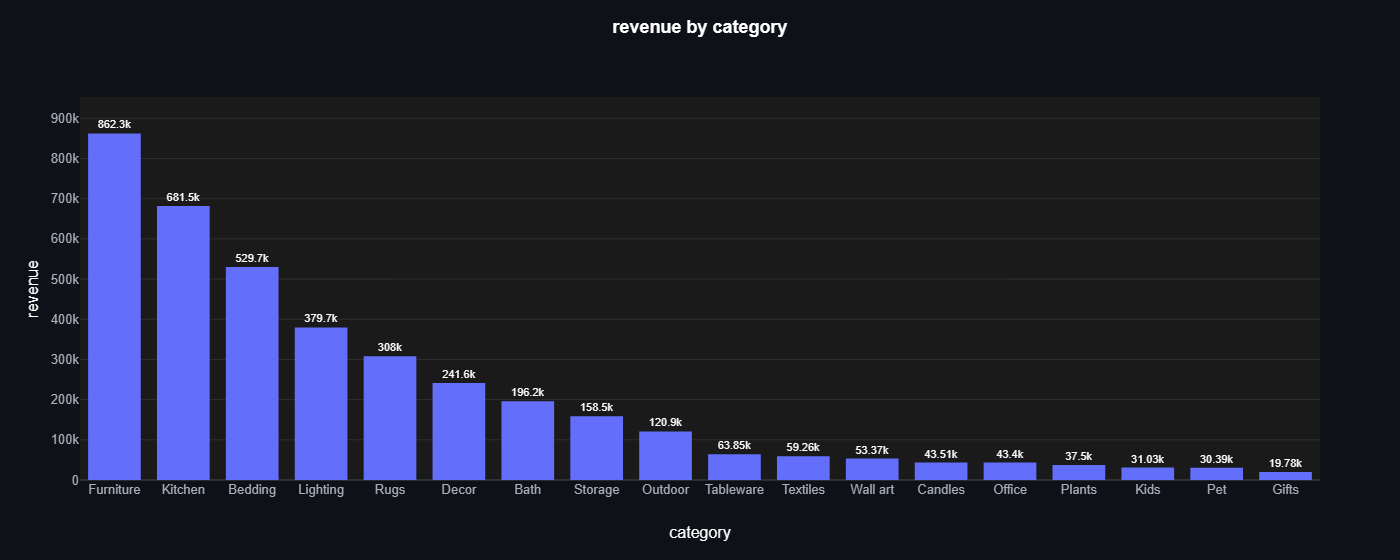

In [3]:
ev.bar_plot(revenue, "category", "revenue")

## Parameter tour

Every option, one change per chart. Defaults and accepted values are quoted from the
docstring (`help(ev.bar_plot)`).

### Data and aggregation

**`agg`** (`{"sum", "mean", "median", "min", "max", "count"} or None, default None`):
`None` plots each row as-is. Raw rows, one per order here, need it: `agg="sum"` adds
up the revenue of each region's orders.

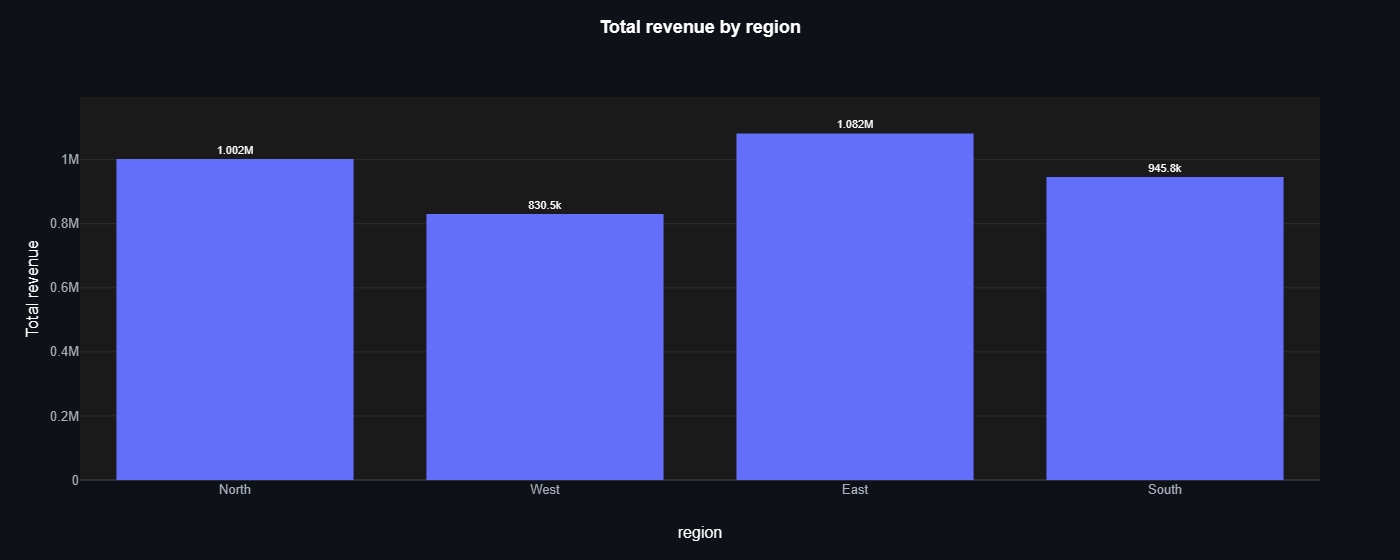

In [4]:
orders = db.sql("""
    SELECT order_date, category, region, warehouse, revenue, profit
    FROM orders
        JOIN products USING (product_id)
        JOIN customers USING (customer_id)
    ORDER BY order_id
""").df()

ev.bar_plot(orders, "region", "revenue", agg="sum")

**`color`** (`str or None, default None`): the column that splits the bars into
coloured series (long format). Each region's revenue, split by the warehouse that
shipped the order.

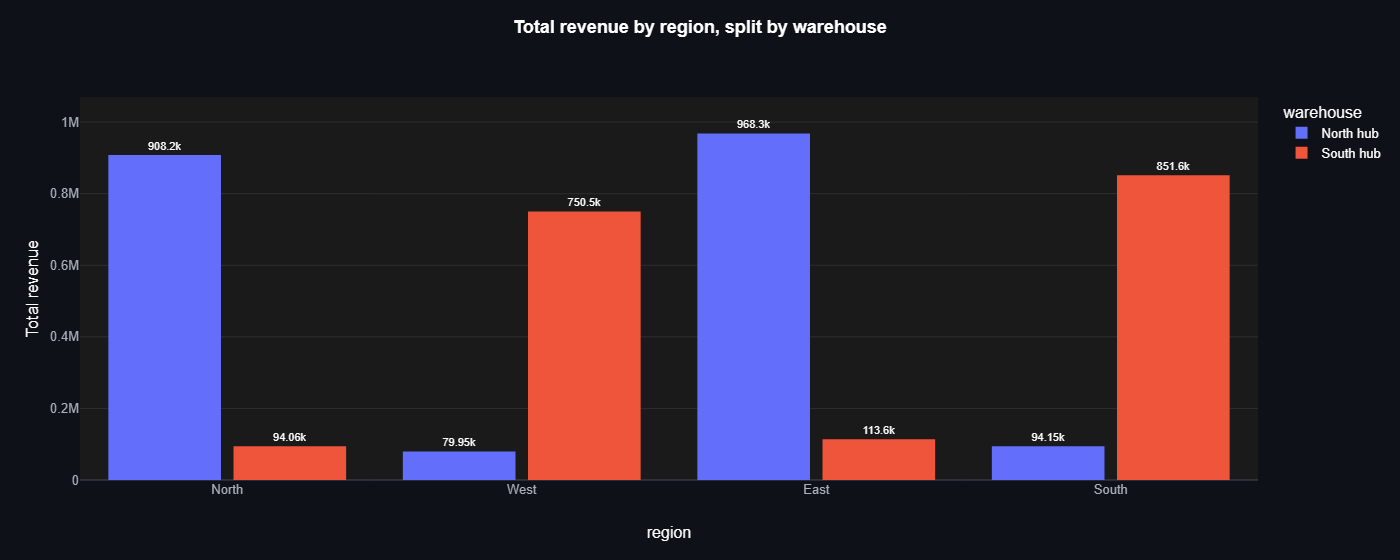

In [5]:
ev.bar_plot(orders, "region", "revenue", color="warehouse", agg="sum")

**`y` as a list**: a wide table, with several measures side by side in columns, gives
one series per column, named after it. Here, the six biggest categories' revenue next
to their profit.

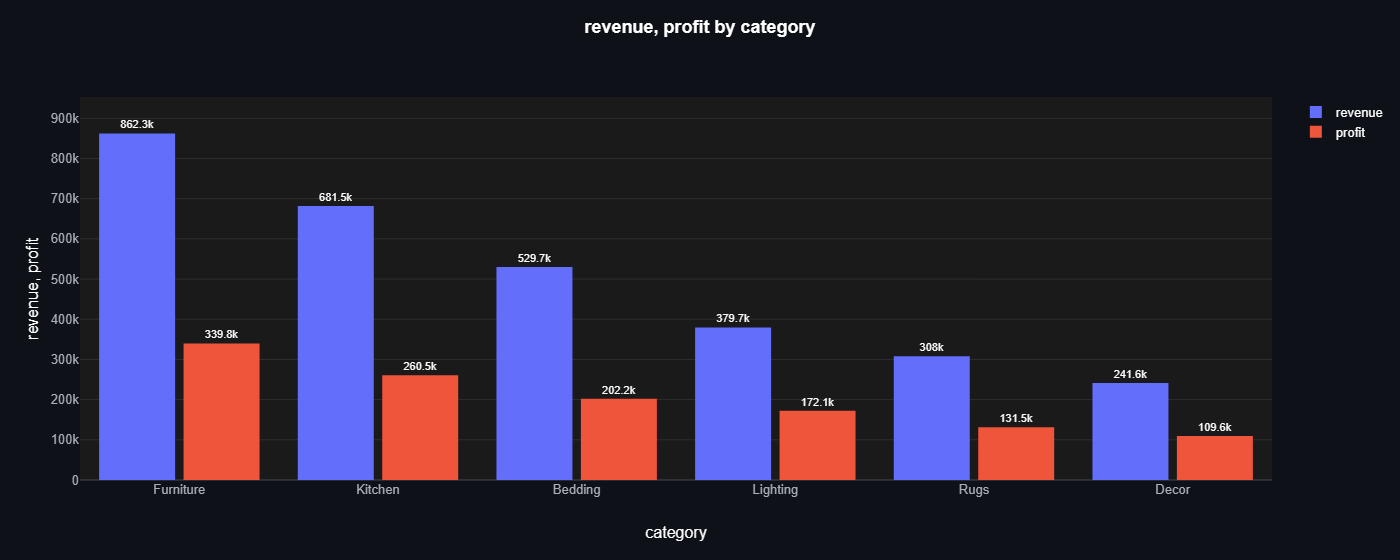

In [6]:
categories = db.sql("""
    SELECT category,
           SUM(revenue) AS revenue,
           SUM(profit)  AS profit,
           COUNT(*)     AS orders
    FROM orders JOIN products USING (product_id)
    GROUP BY category
    ORDER BY revenue DESC
    LIMIT 6
""").df()

ev.bar_plot(categories, "category", ["revenue", "profit"])

**`hover`** (`str, list of str or None, default None`): extra columns shown on hover.
Only with `agg=None`: an aggregated bar has no single value for them. Hover over a bar
in Jupyter to see each category's order count; the static image can't show it.

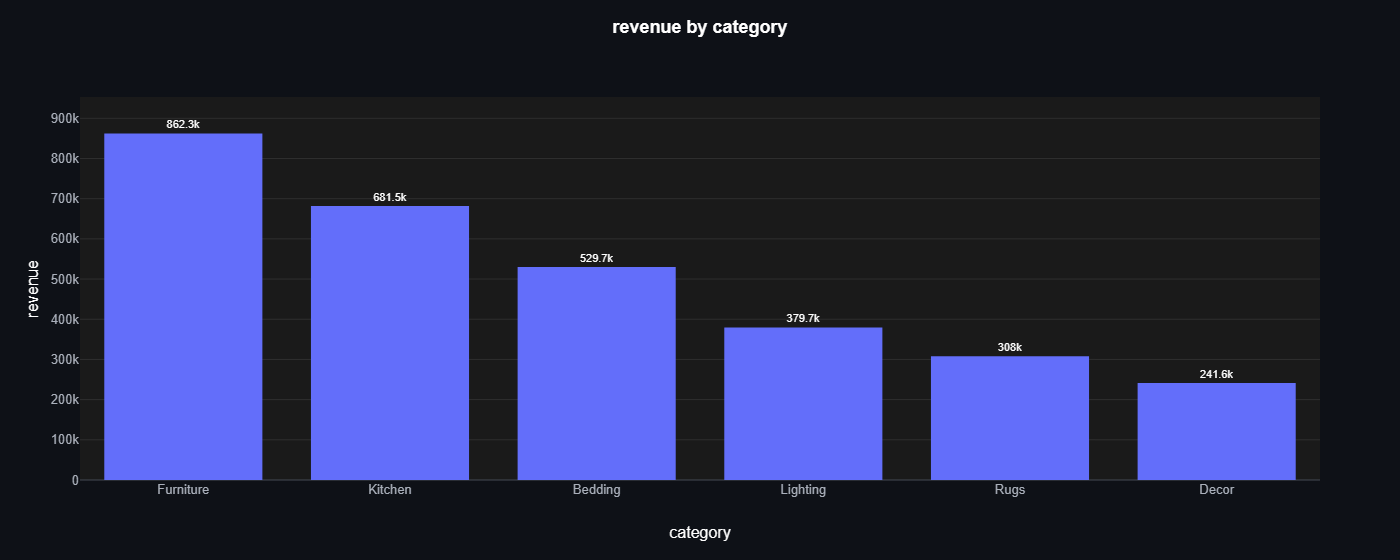

In [7]:
ev.bar_plot(categories, "category", "revenue", hover="orders")

**`ci`** (`{"bootstrap", "sem"} or None, default None`): error bars, a confidence
interval around each bar. `"bootstrap"` works for the mean and the median, `"sem"`
(mean ± z·standard error) for the mean only. It needs the raw rows behind each bar,
so `agg="mean"` or `"median"`. Here, mean order value per variant of the checkout
A/B/C test. With error bars, the labels move to the base of the bars, clear of the
whiskers.

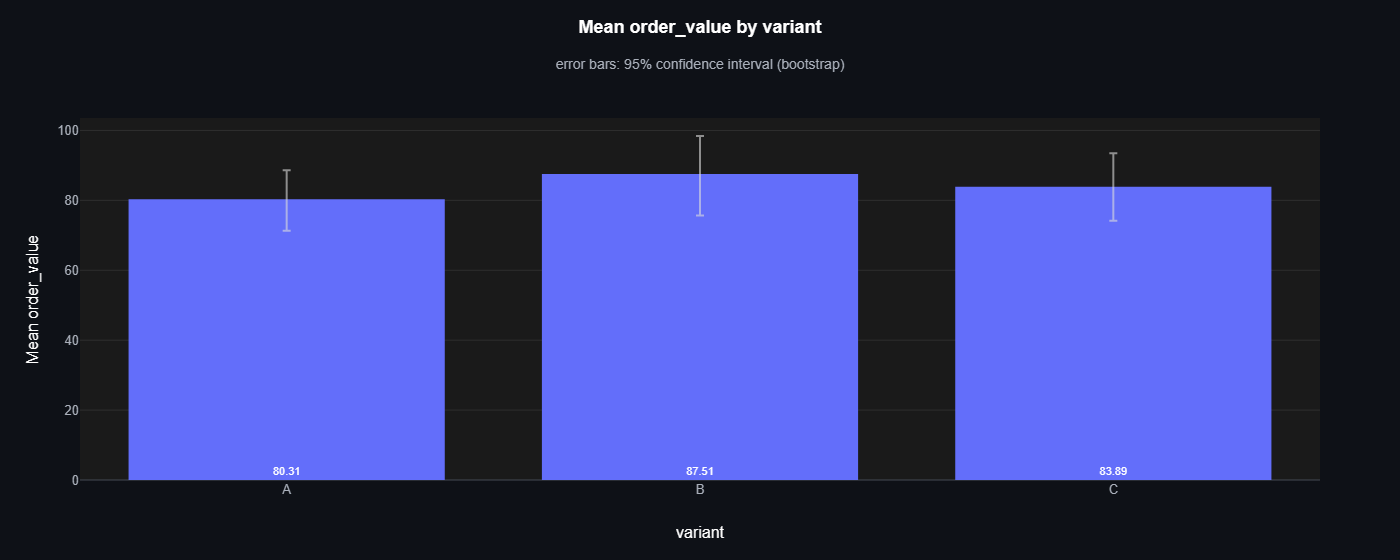

In [8]:
checkout = db.sql("""
    SELECT variant, device, order_value
    FROM checkout_test
    ORDER BY variant
""").to_arrow_table()

ev.bar_plot(checkout, "variant", "order_value", agg="mean", ci="bootstrap")

**`ci_level`** (`float, default 0.95`): the confidence level, strictly between 0 and 1.
A 90 % interval from the standard error is narrower than the 95 % one above.

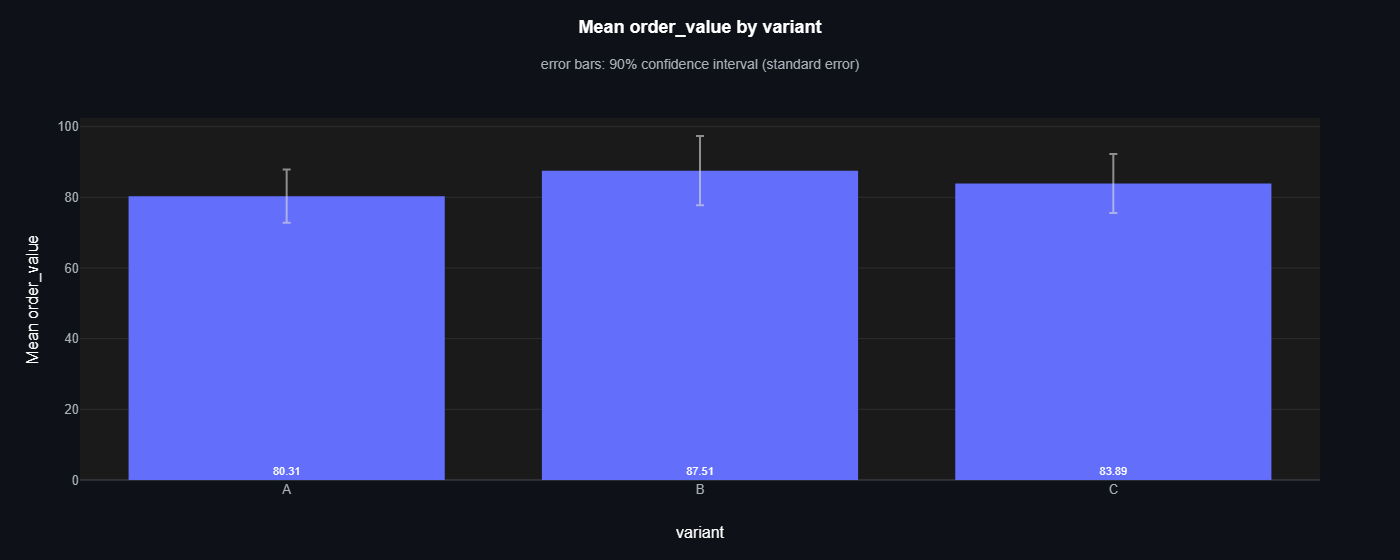

In [9]:
ev.bar_plot(checkout, "variant", "order_value", agg="mean", ci="sem", ci_level=0.9)

**`n_boot`** (`int, default 2000`): bootstrap resamples per bar. **`random_state`**
(`int, numpy Generator or None, default 0`): the seed of the bootstrap. The fixed
default draws the same intervals on every run; `None` draws new ones. More resamples
give steadier interval ends; a different seed moves them slightly.

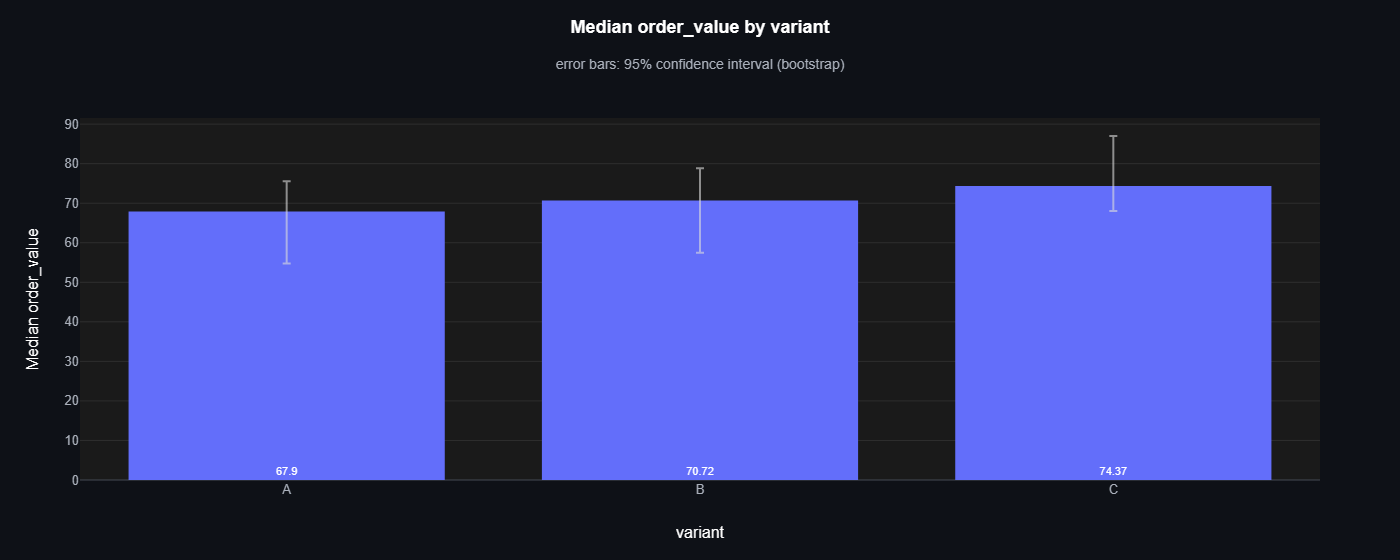

In [10]:
ev.bar_plot(
    checkout,
    "variant",
    "order_value",
    agg="median",
    ci="bootstrap",
    n_boot=10_000,
    random_state=42,
)

**`min_n`** (`int or None, default 30`): with `agg="mean"` or `"median"`, bars built
from fewer rows than this are hatched and marked ⚠: their value is unreliable. Over
the Black Friday weekend of 2025, most categories had only a handful of orders; here
the threshold is lowered to 10.

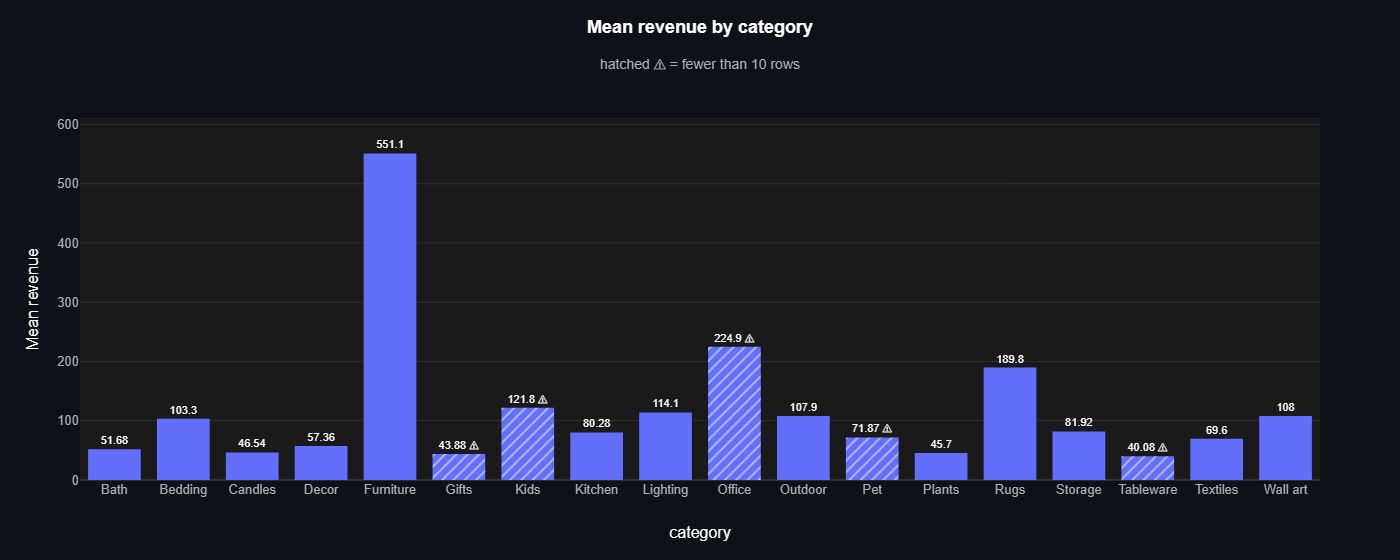

In [11]:
weekend = db.sql("""
    SELECT category, revenue
    FROM orders JOIN products USING (product_id)
    WHERE order_date BETWEEN '2025-11-28' AND '2025-12-01'
    ORDER BY category
""")

ev.bar_plot(weekend, "category", "revenue", agg="mean", min_n=10)

### Ordering

**`sort_by`** (`{"value", "x"} or None, default None`): `None` keeps the query's order.
`"value"` orders categories by bar value; `"x"` by the category itself. The raw orders
come in the order they were placed, so the regions appear in the order of their first
order; sorting by value ranks them.

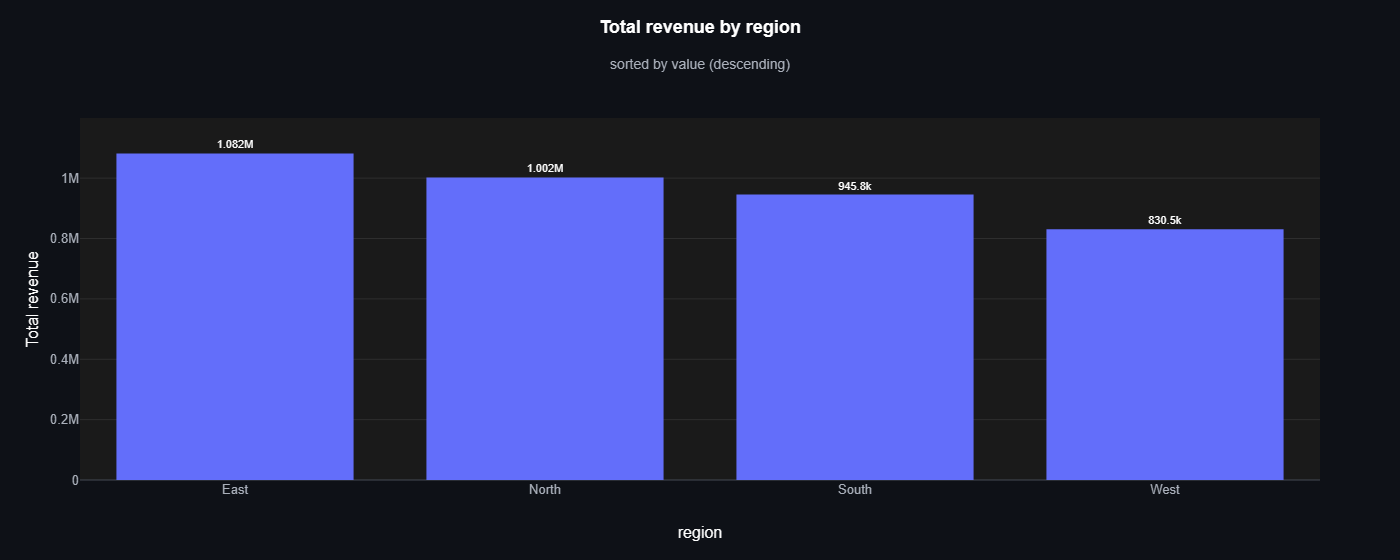

In [12]:
ev.bar_plot(orders, "region", "revenue", agg="sum", sort_by="value")

**`ascending`** (`bool, default False`): the sort direction for `sort_by`; the default
puts the largest first. Categories sorted by name, A to Z:

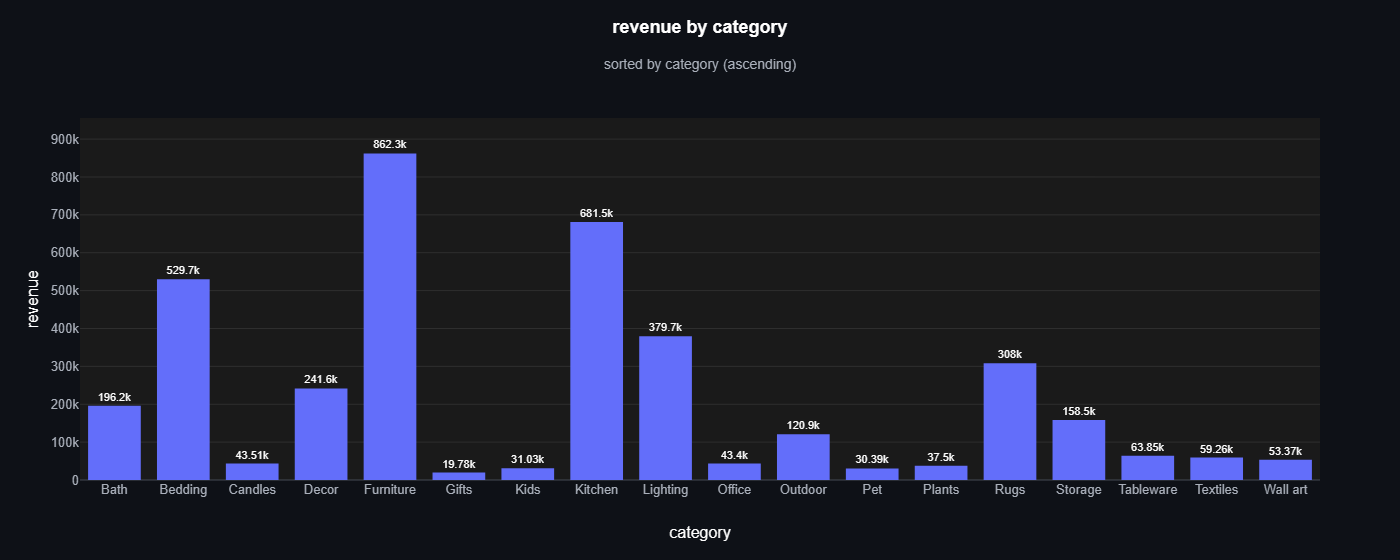

In [13]:
ev.bar_plot(revenue, "category", "revenue", sort_by="x", ascending=True)

**`top_n`** (`int or None, default None`): keep the first N categories after sorting.
The subtitle says how many were cut, so the chart never hides that it is partial.

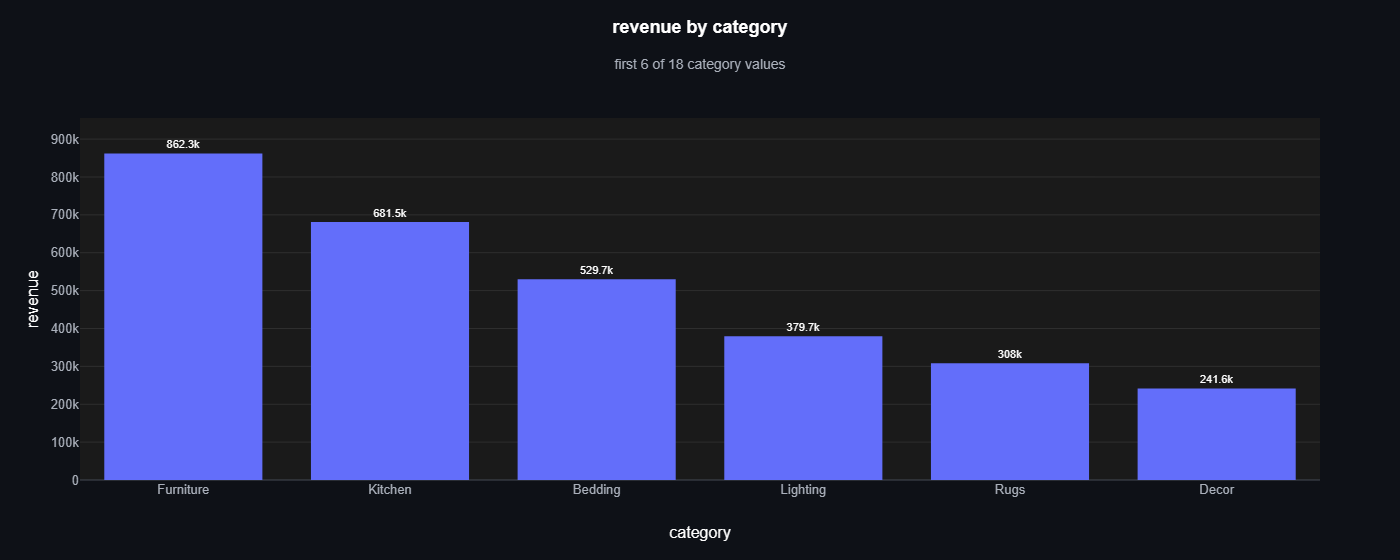

In [14]:
ev.bar_plot(revenue, "category", "revenue", top_n=6)

**`other`** (`bool, default False`): with `top_n`, add one "Other" bar for the
categories cut. With `agg=None` the cut values are added up: right for totals and
counts, wrong for averages and rates. These are revenue totals, so adding up is right,
and the twelve smallest categories together turn out to bring nearly as much as
Furniture.

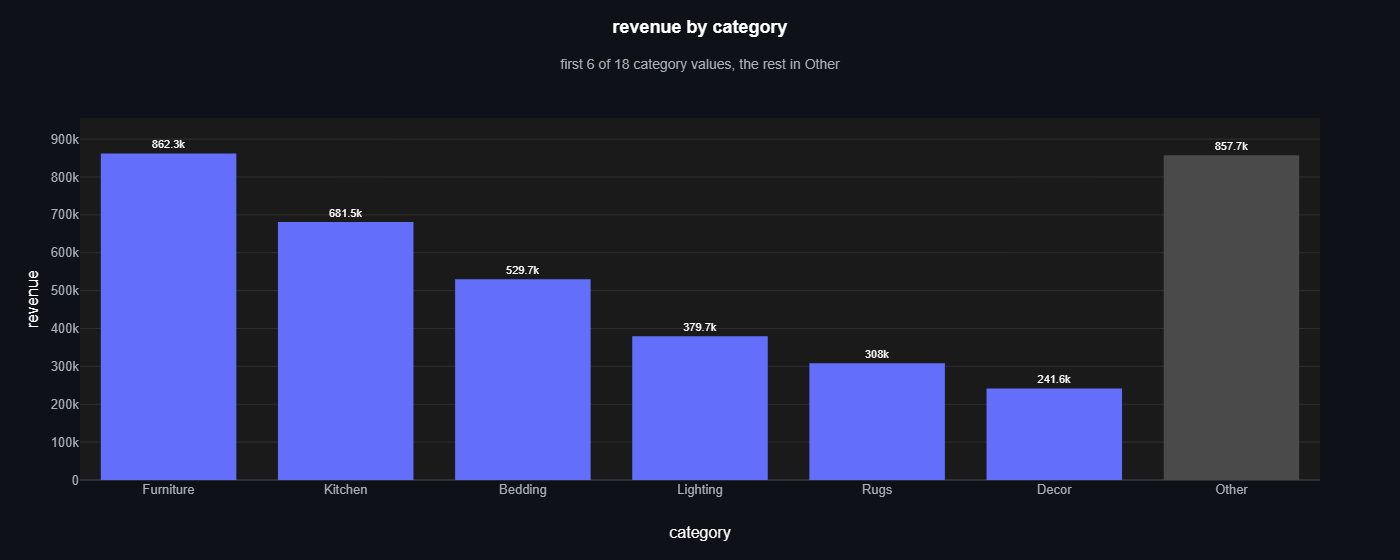

In [15]:
ev.bar_plot(revenue, "category", "revenue", top_n=6, other=True)

### Labels

**`show_values`** (`bool, default True`): write each bar's value on it. Turned off, the
chart relies on the axis, and the hover still has every value.

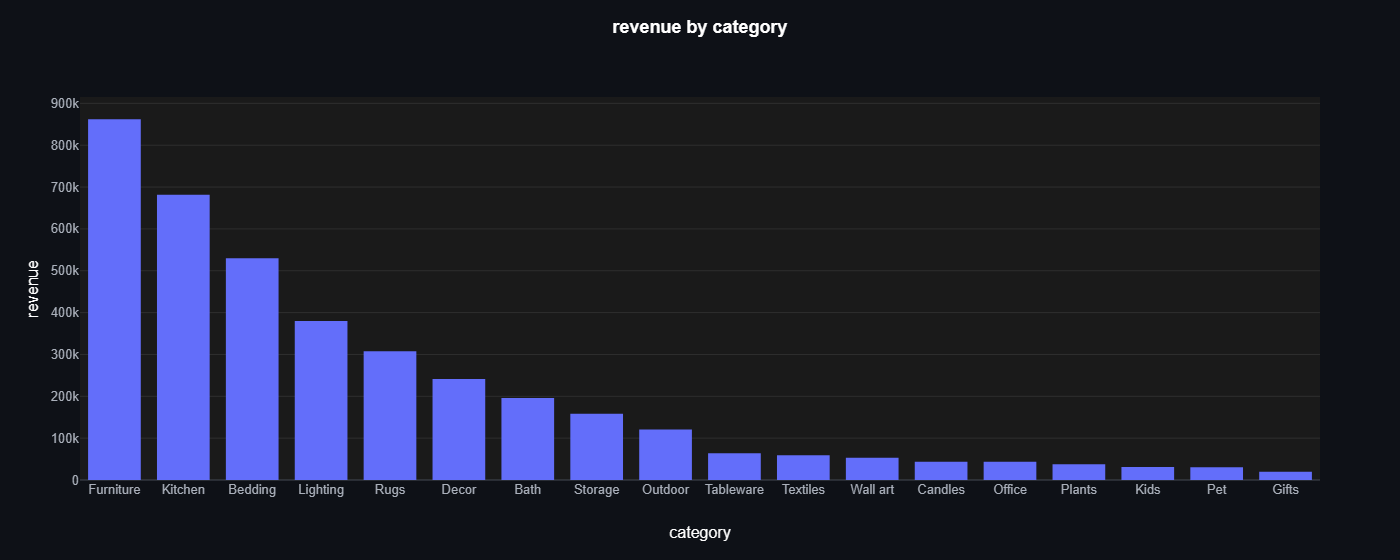

In [16]:
ev.bar_plot(revenue, "category", "revenue", show_values=False)

**`value_format`** (`str or None, default None`): a Python format spec for values in
labels, hover and reference lines. `None` gives four significant digits with k, M, B
for thousands, millions, billions, at most 0.05 % from the value. Full numbers with
thousands separators, for six categories:

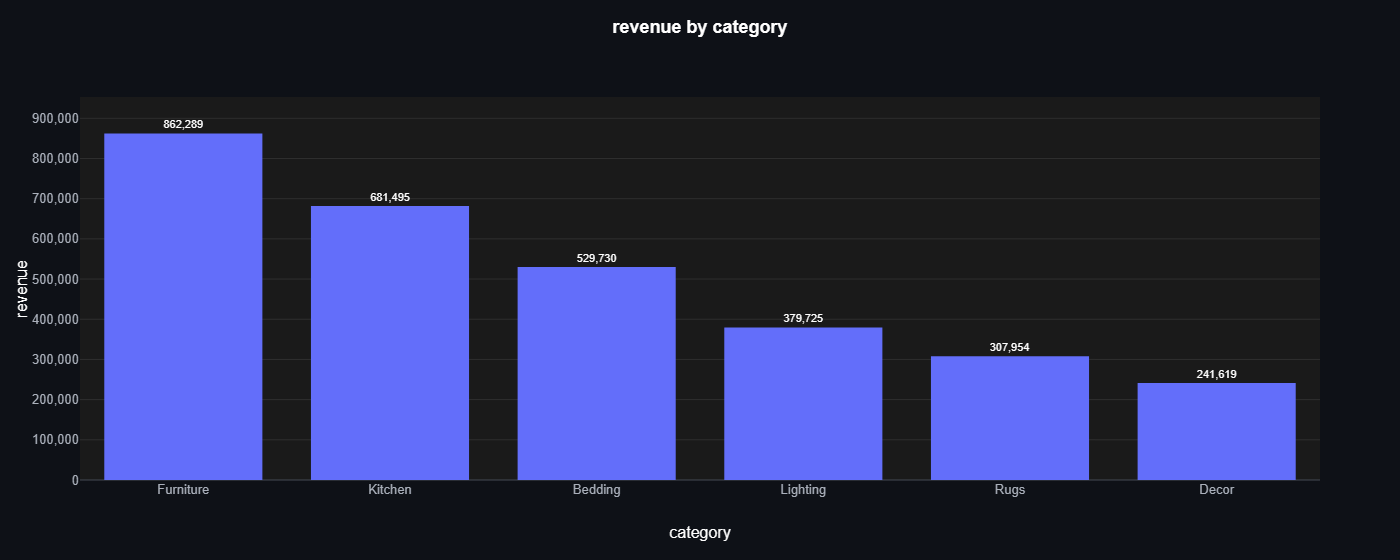

In [17]:
ev.bar_plot(categories, "category", "revenue", value_format=",.0f")

**`text_position`** (`{"outside", "inside", "auto"} or None, default None`): where
labels sit. `None`: outside for side-by-side bars, inside for stacked ones, and inside
at the base of the bar with `ci`.

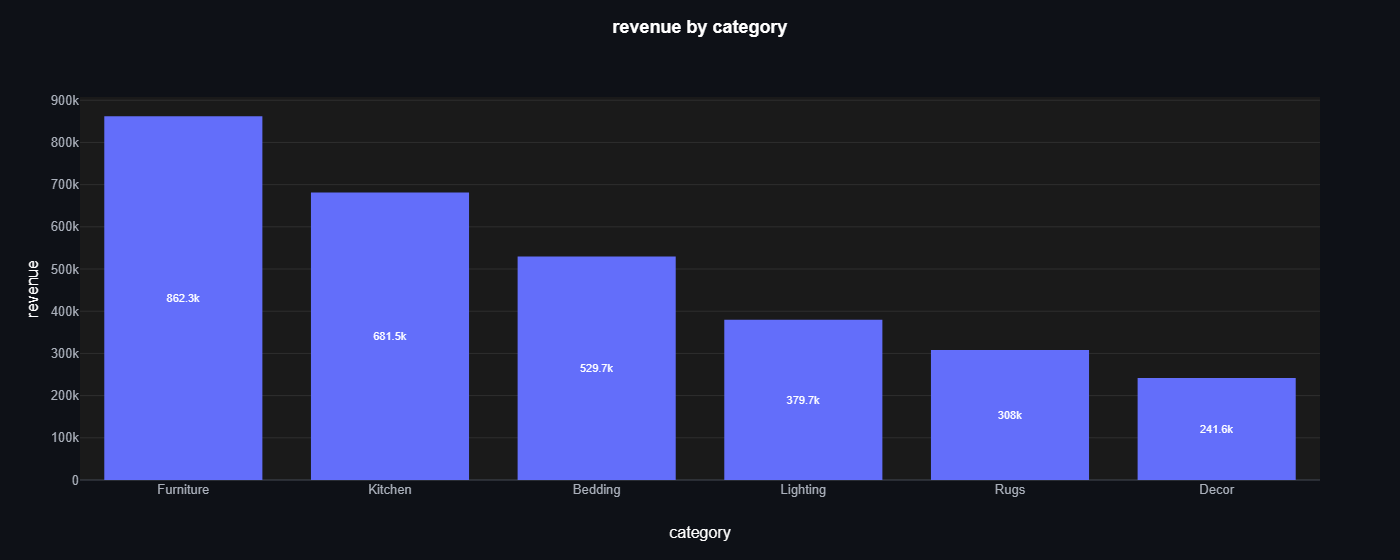

In [18]:
ev.bar_plot(categories, "category", "revenue", text_position="inside")

**`show_pct_of_total`** (`bool, default False`): add each bar's share of the sum of
all bars drawn to its label and hover.

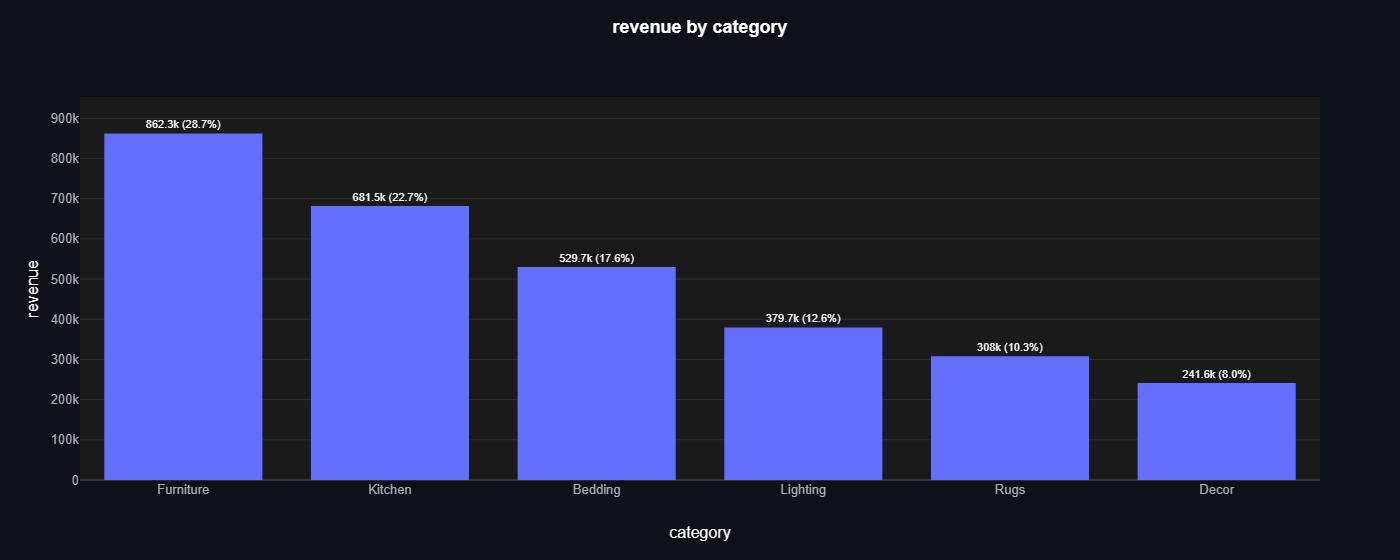

In [19]:
ev.bar_plot(categories, "category", "revenue", show_pct_of_total=True)

**`show_n`** (`bool, default False`): add each bar's row count ("n=42") to its label.
It needs `agg`; the count is in the hover whenever `agg` is set.

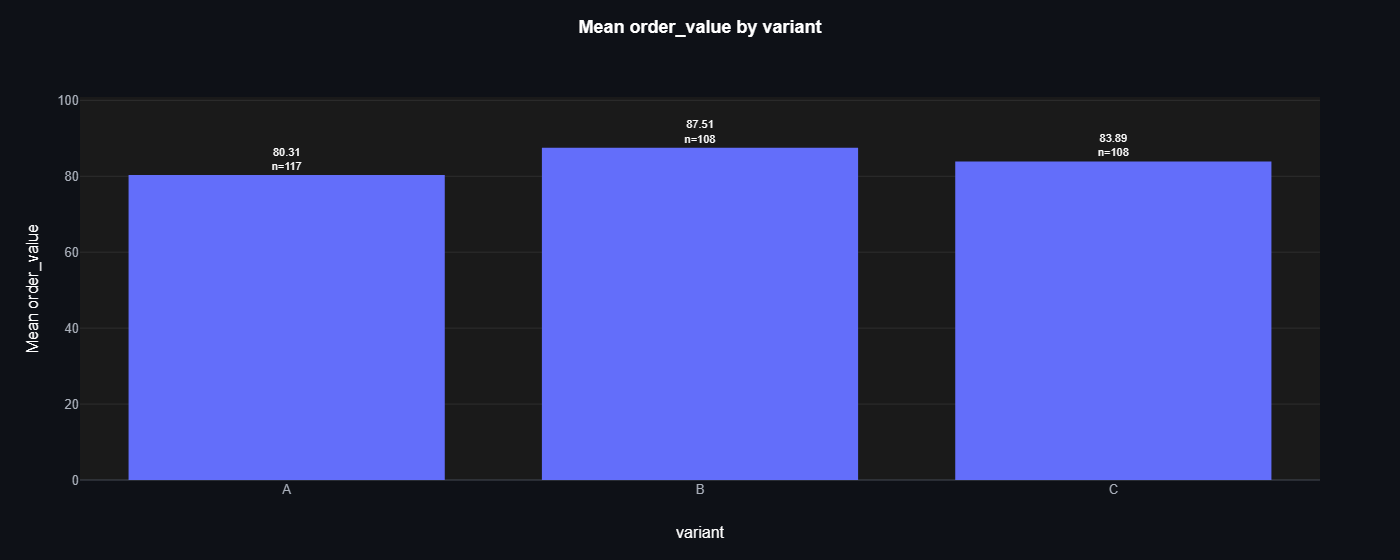

In [20]:
ev.bar_plot(checkout, "variant", "order_value", agg="mean", show_n=True)

### Colour

**`highlight`** (`str, list of str or None, default None`): categories to emphasise;
the other bars use the theme's dimmed colour. One series only.

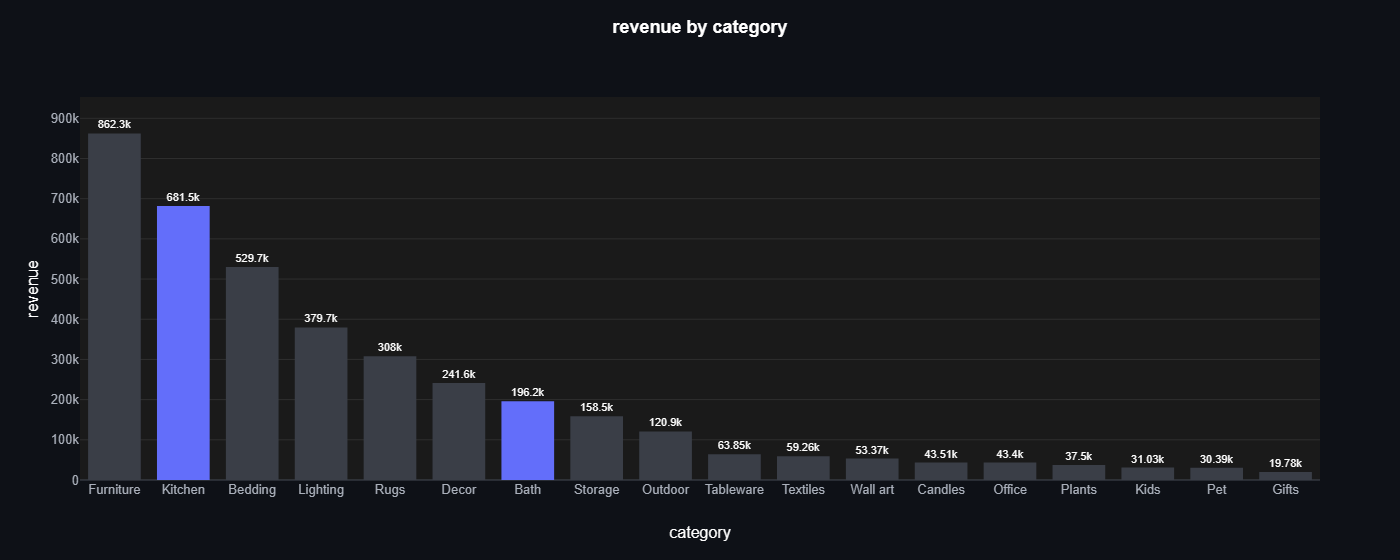

In [21]:
ev.bar_plot(revenue, "category", "revenue", highlight=["Kitchen", "Bath"])

**`color_map`** (`mapping of str to str or None, default None`): a fixed colour per
series, so a category looks the same in every chart. Hex, `rgb()` or `rgba()`; it must
cover every series drawn and may hold others, so one map can serve a whole report.

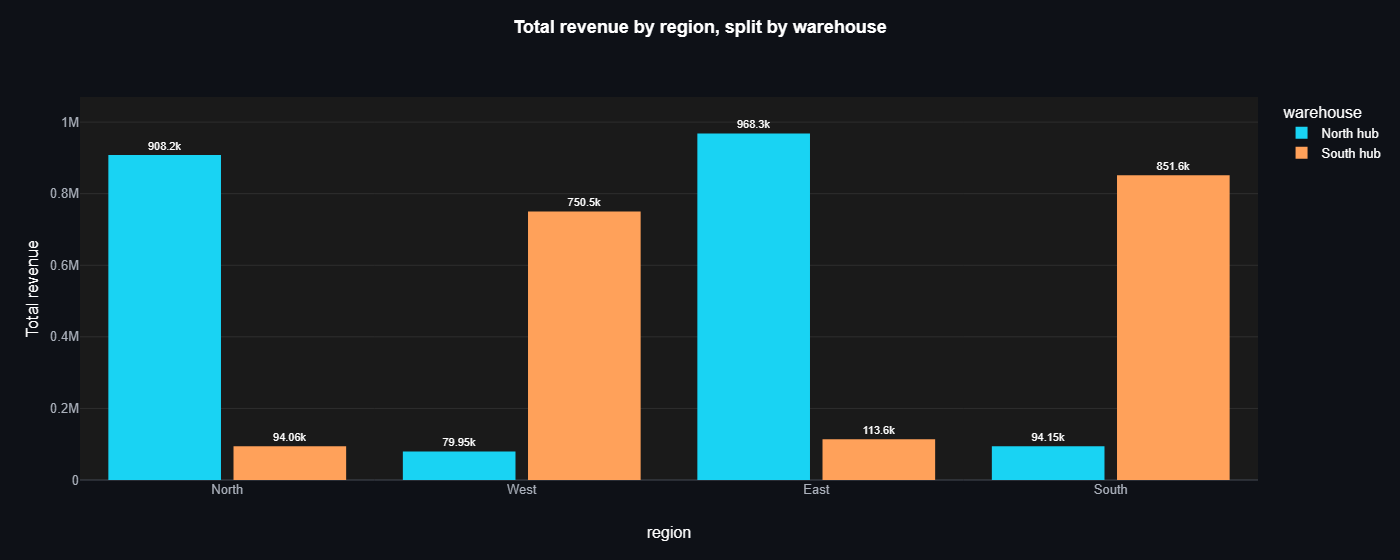

In [22]:
WAREHOUSE_COLORS = {"North hub": "#19D3F3", "South hub": "#FFA15A"}

ev.bar_plot(
    orders,
    "region",
    "revenue",
    color="warehouse",
    agg="sum",
    color_map=WAREHOUSE_COLORS,
)

**`color_by_value`** (`{"sequential", "diverging", "sign"} or None, default None`):
colour each bar by its own value. `"sequential"` runs low to high, with a colour bar;
`"diverging"` goes in two directions from `color_midpoint`; `"sign"` uses the theme's
positive and negative colours either side of it. One series only.

Diverging suits a change that can go either way. The query compares each category's
2025 revenue with 2024's; the April 2025 price rise left most categories down.

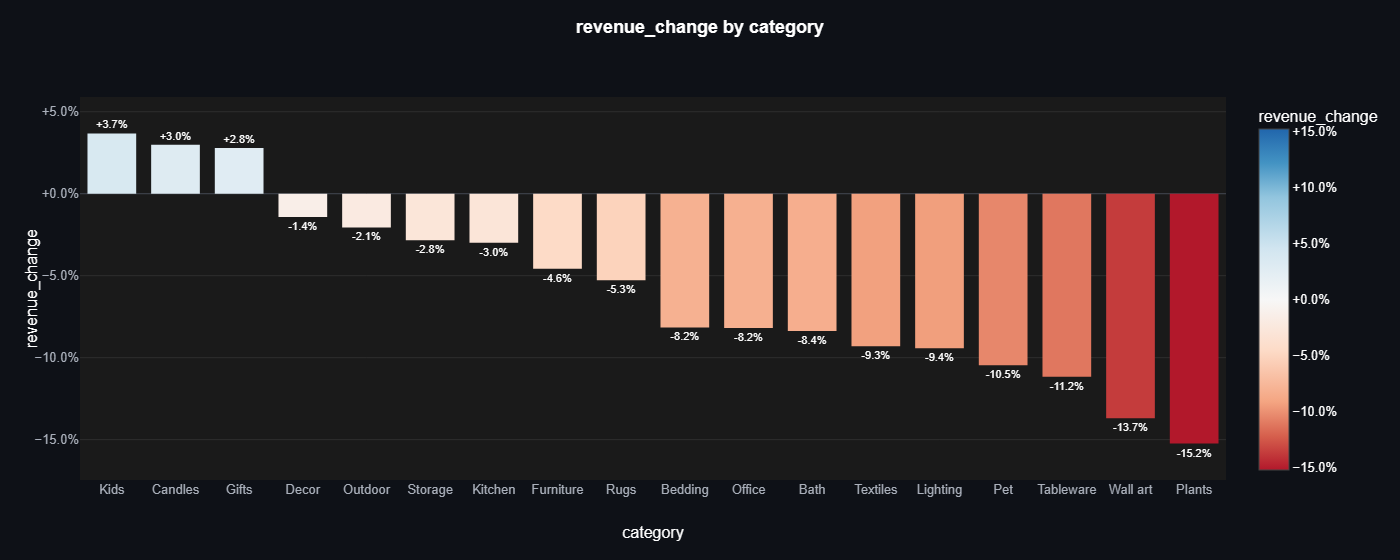

In [23]:
change = db.sql("""
    SELECT category,
           SUM(revenue) FILTER (WHERE year(order_date) = 2025)
             / SUM(revenue) FILTER (WHERE year(order_date) = 2024) - 1 AS revenue_change
    FROM orders JOIN products USING (product_id)
    GROUP BY category
    ORDER BY revenue_change DESC
""").pl()

ev.bar_plot(
    change,
    "category",
    "revenue_change",
    color_by_value="diverging",
    value_format="+.1%",
)

**`colorscale`** (`str, list of (float, str) or None, default None`): any Plotly colour
scale, by name or as stops, for `"sequential"` or `"diverging"`. `None` uses the
theme's scale.

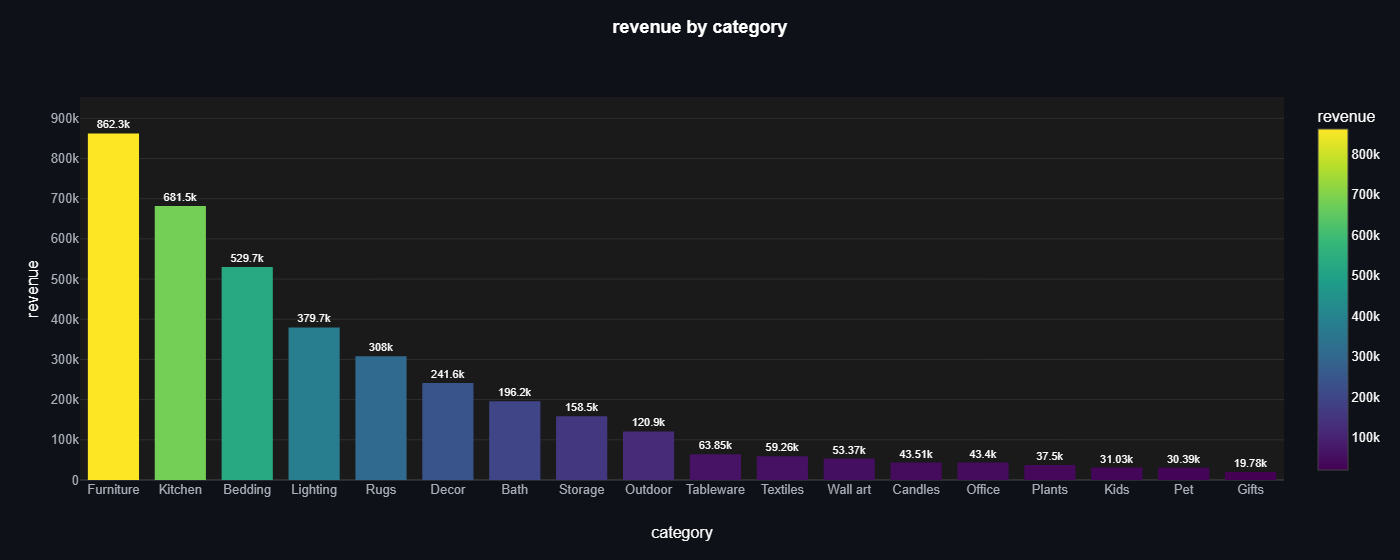

In [24]:
ev.bar_plot(
    revenue,
    "category",
    "revenue",
    color_by_value="sequential",
    colorscale="Viridis",
)

**`color_midpoint`** (`float or None, default None`): the value where `"diverging"`
and `"sign"` change colour; `None` means 0. Every category but three lost revenue, so
against 0 the chart is nearly all red. Against the company-wide change of −5.5 %, it
splits the categories that held up from the ones that fell hardest.

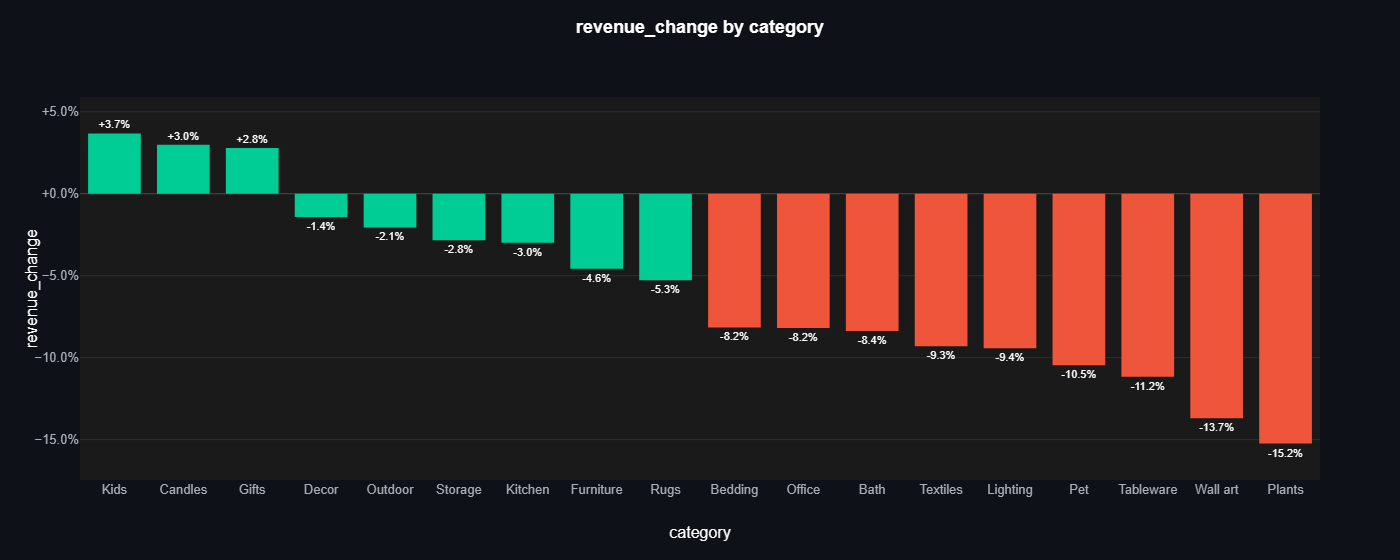

In [25]:
ev.bar_plot(
    change,
    "category",
    "revenue_change",
    color_by_value="sign",
    color_midpoint=-0.055,
    value_format="+.1%",
)

### Reference lines

**`avg_line`** (`bool, default False`): a dashed line at the average bar ("Other"
left out).

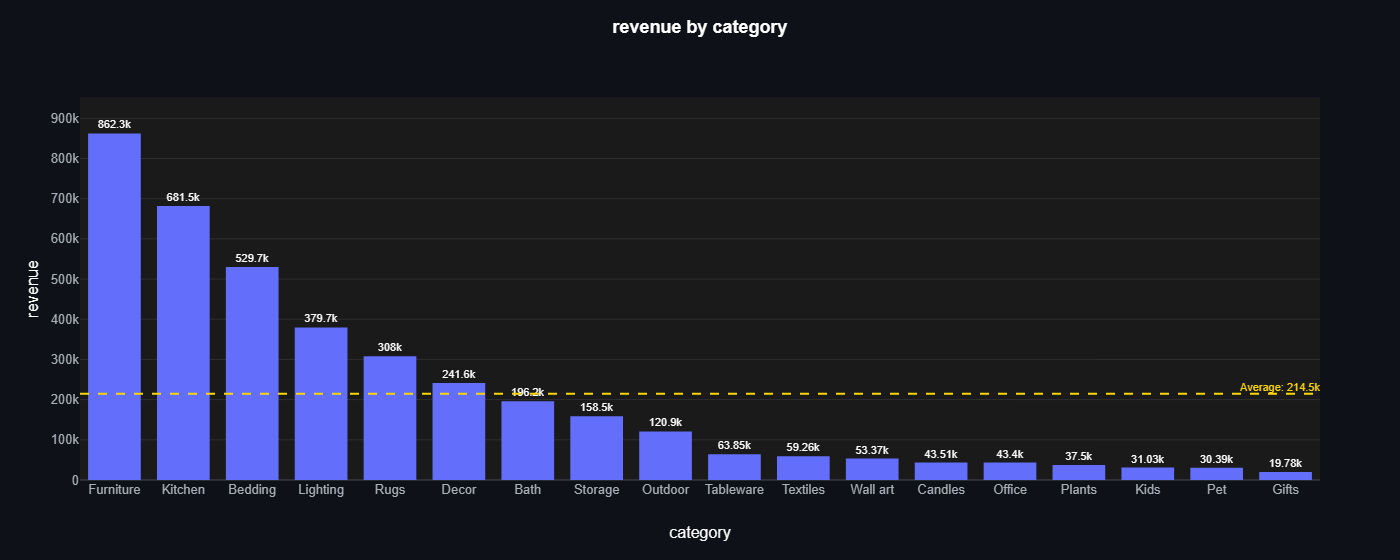

In [26]:
ev.bar_plot(revenue, "category", "revenue", avg_line=True)

**`target`** (`float or None, default None`): a dotted line at a target value,
labelled.

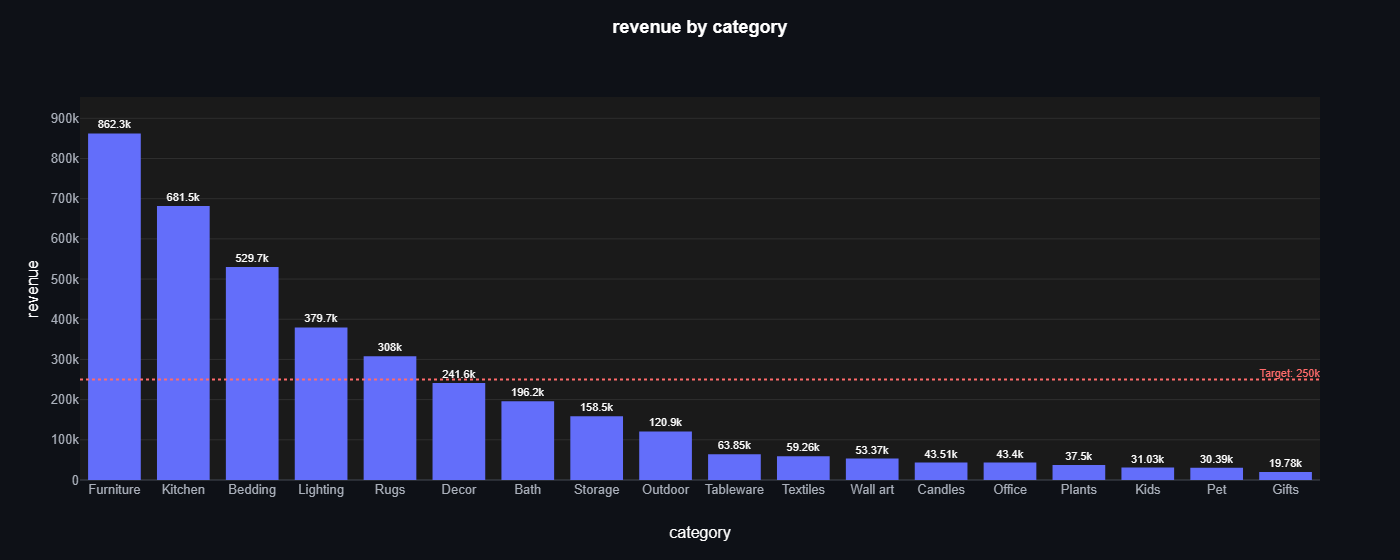

In [27]:
ev.bar_plot(revenue, "category", "revenue", target=250_000)

### Layout

**`orientation`** (`{"vertical", "horizontal"}, default "vertical"`): `"horizontal"`
puts categories down the page, the first one at the top: good for long labels and many
categories. The figure grows taller with the number of categories.

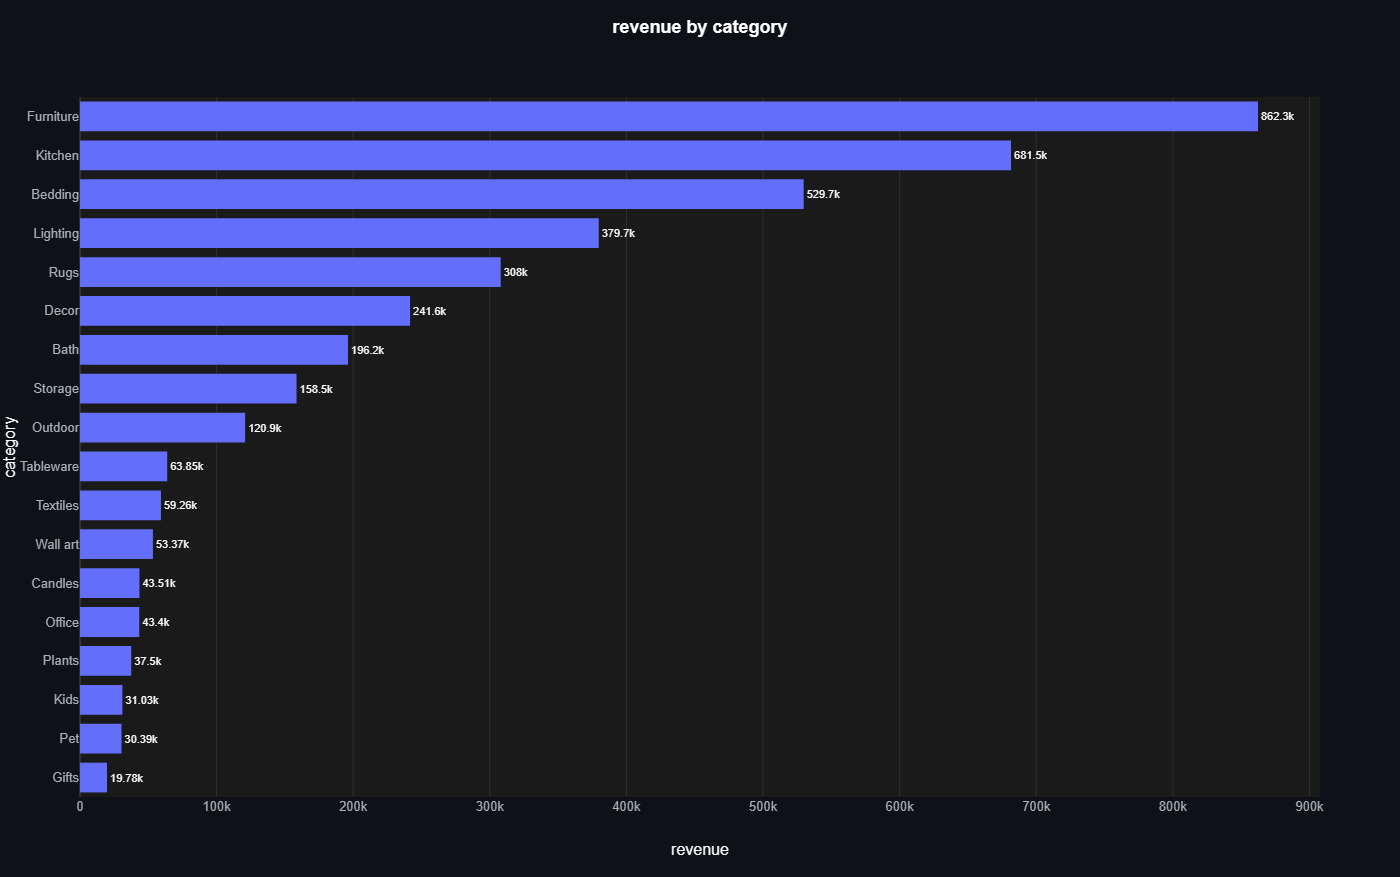

In [28]:
ev.bar_plot(revenue, "category", "revenue", orientation="horizontal")

**`barmode`** (`{"group", "stack", "percent"}, default "group"`): how several series
share a category: side by side, stacked (with the total above each stack), or stacked
to 100 % (each segment's share).

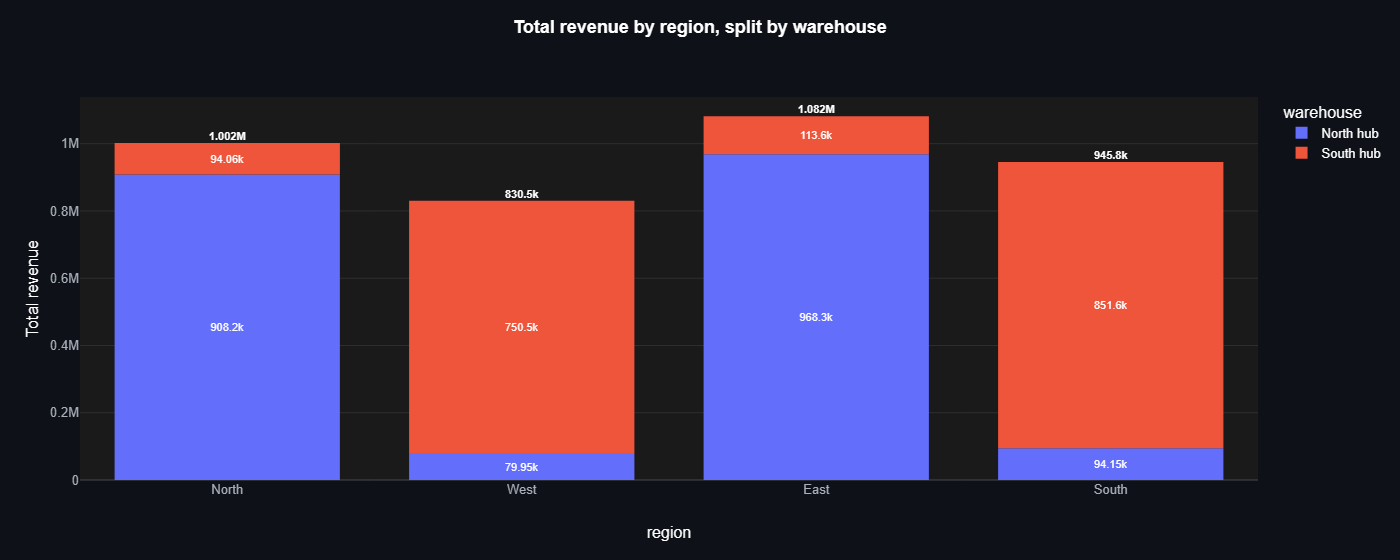

In [29]:
ev.bar_plot(orders, "region", "revenue", color="warehouse", agg="sum", barmode="stack")

`"percent"` shows the mix inside each category. Counting orders per region and
warehouse makes the routing plain (*Hidden bimodality: two warehouses*, pattern 3):
the North and East are served by the North hub, the South and West by the South hub,
nine times out of ten.

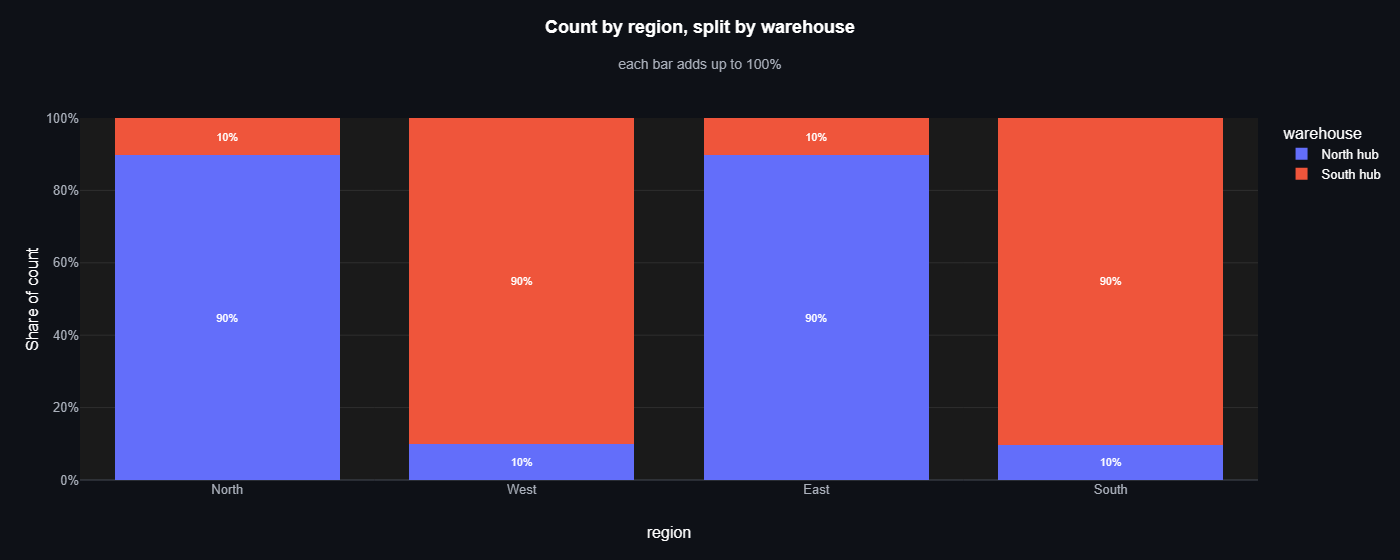

In [30]:
ev.bar_plot(orders, "region", color="warehouse", agg="count", barmode="percent")

**`bargap`** (`float, default 0.15`): the gap between categories, as a fraction of a
category's width (0 to 1). **`bargroupgap`** (`float, default 0.1`): the gap between
the bars of one category.

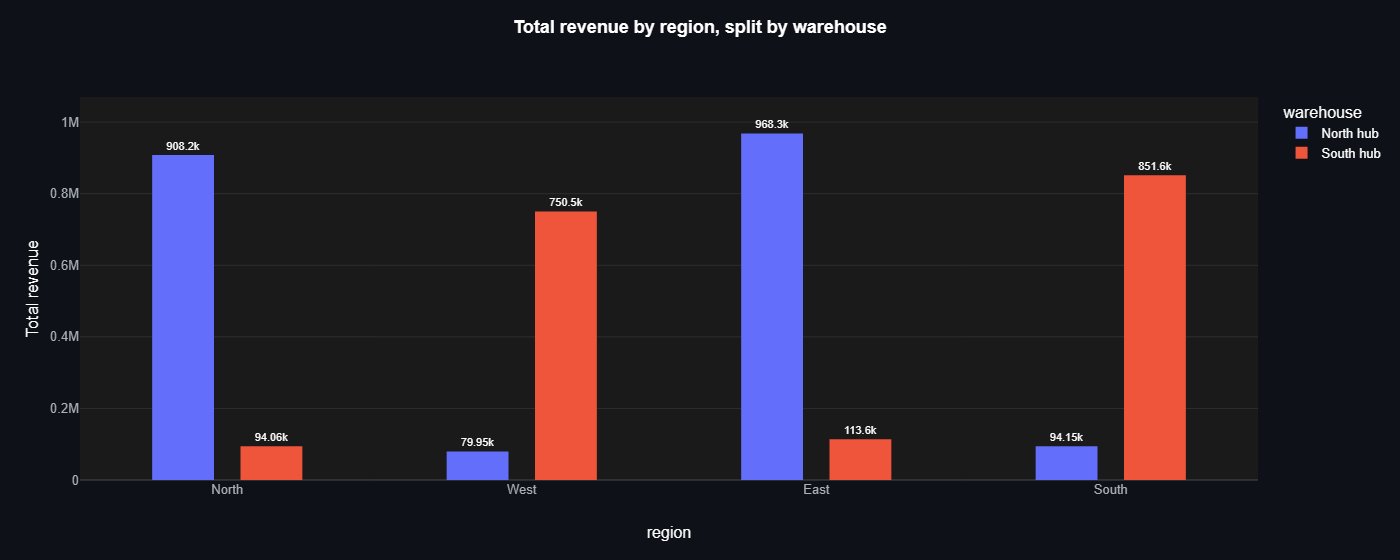

In [31]:
ev.bar_plot(
    orders,
    "region",
    "revenue",
    color="warehouse",
    agg="sum",
    bargap=0.4,
    bargroupgap=0.3,
)

**`title`**, **`subtitle`** (`str or None, default None`): `None` builds them: the title
from the columns, the subtitle from what the chart does to the data (sorting, cut
categories, the interval method, the small-group flag). `""` shows none. A report
title states the finding instead. Dollar signs are safe: Plotly would otherwise read
two of them as a formula.

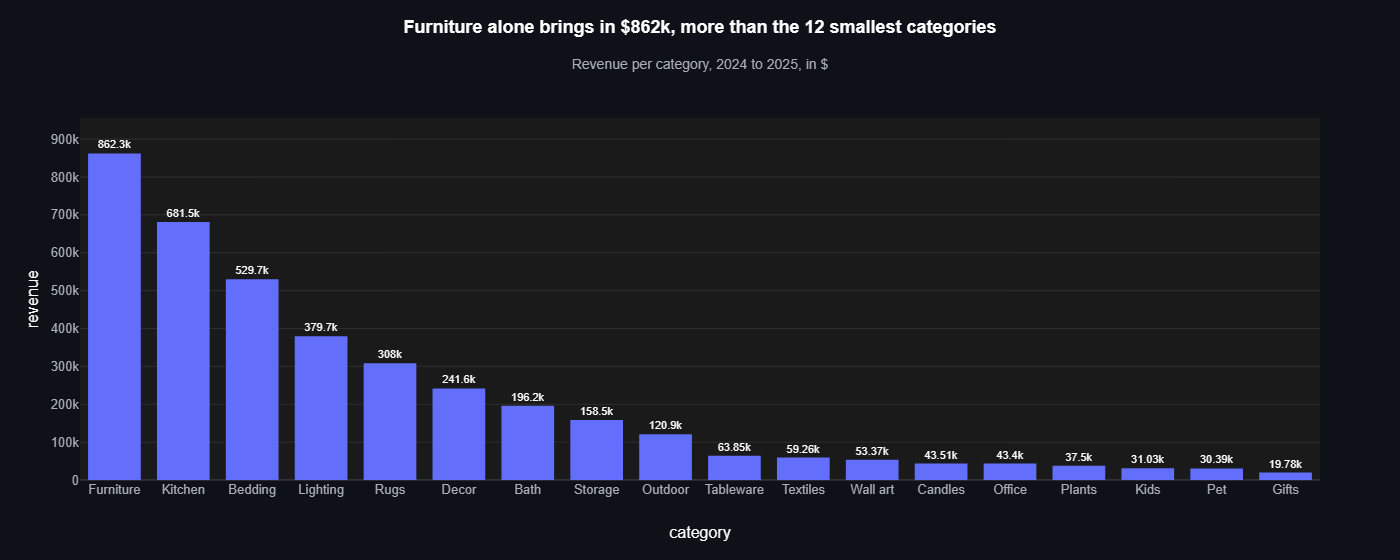

In [32]:
ev.bar_plot(
    revenue,
    "category",
    "revenue",
    title="Furniture alone brings in $862k, more than the 12 smallest categories",
    subtitle="Revenue per category, 2024 to 2025, in $",
)

**`x_title`**, **`y_title`** (`str or None, default None`): axis titles of the `x`
and `y` slots, wherever `orientation` draws them. `None` uses the column name (`y`
with its aggregate); `""` shows none. **`width`**, **`height`** (`int or None, default
None`): size in px. `width=None` uses `ev.get_config().width`; `height=None` is 0.4 x
the width, taller when horizontal bars need it.

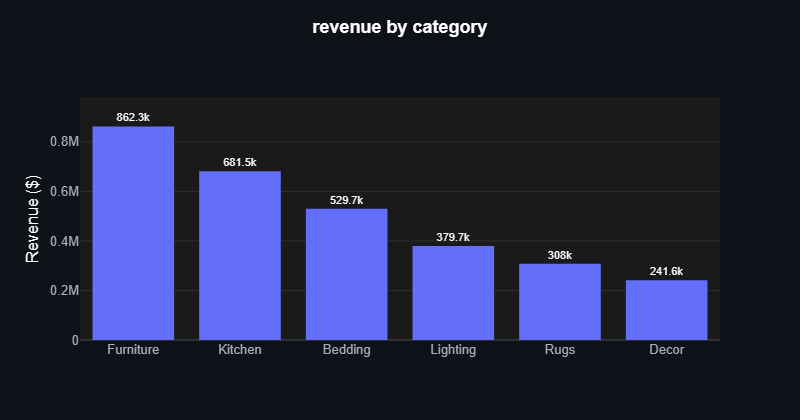

In [33]:
ev.bar_plot(
    categories,
    "category",
    "revenue",
    x_title="",
    y_title="Revenue ($)",
    width=800,
    height=420,
)

### Theme

**`theme`** (`{"dark", "light"}, Theme or None, default None`): the theme for this
chart; `None` uses the global one (`ev.set_theme`).

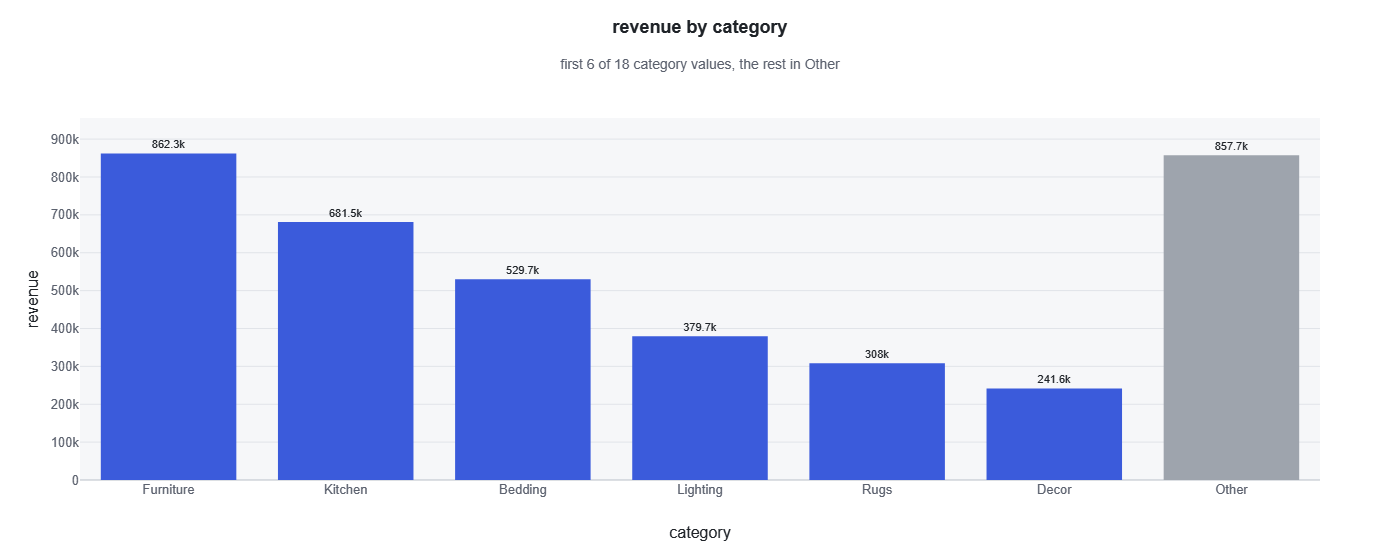

In [34]:
ev.bar_plot(revenue, "category", "revenue", top_n=6, other=True, theme="light")

## Combinations

Professional charts take more options, never more code.

**How concentrated is revenue across categories?** (*Long-tail product categories*,
pattern 5.) Straight from the raw orders: total per category, the six largest ranked,
the long tail folded into one bar, each bar's share of the whole, laid out for long
labels.

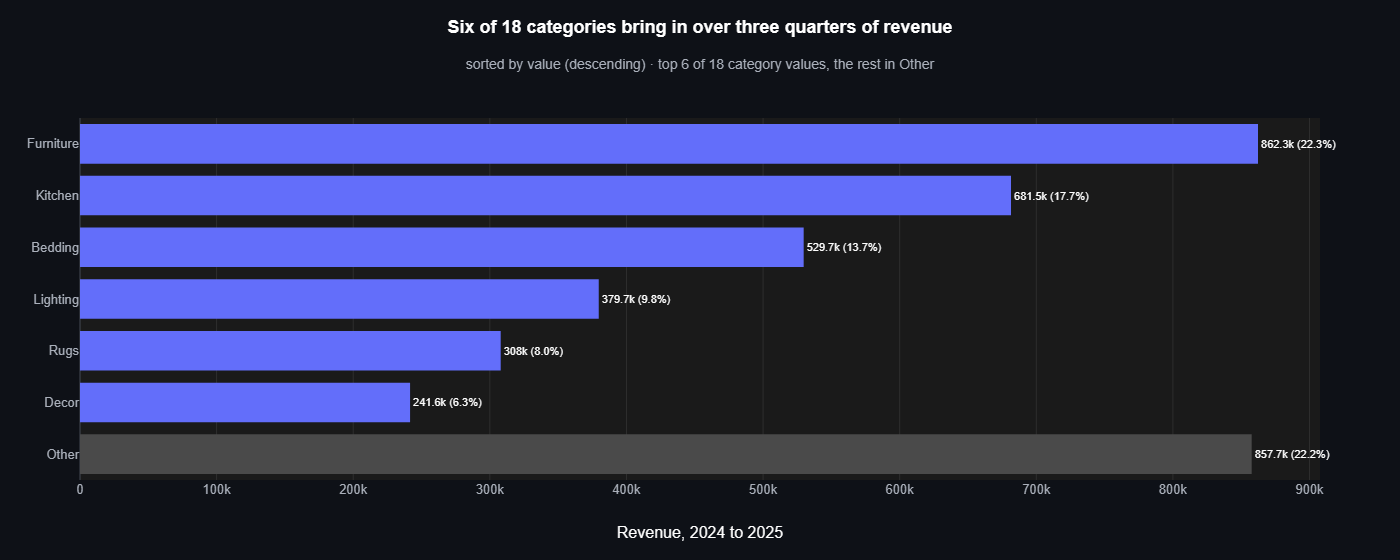

In [35]:
ev.bar_plot(
    orders,
    "category",
    "revenue",
    agg="sum",
    sort_by="value",
    top_n=6,
    other=True,
    show_pct_of_total=True,
    orientation="horizontal",
    title="Six of 18 categories bring in over three quarters of revenue",
    x_title="",
    y_title="Revenue, 2024 to 2025",
)

**Did checkout variant B really win?** (*Differences that look real but aren't*,
pattern 10.) Mean order value per variant and device, with bootstrap intervals and
each bar's sample size. B's bars are the tallest on both devices, but every interval
overlaps the others: there is no winner to ship.

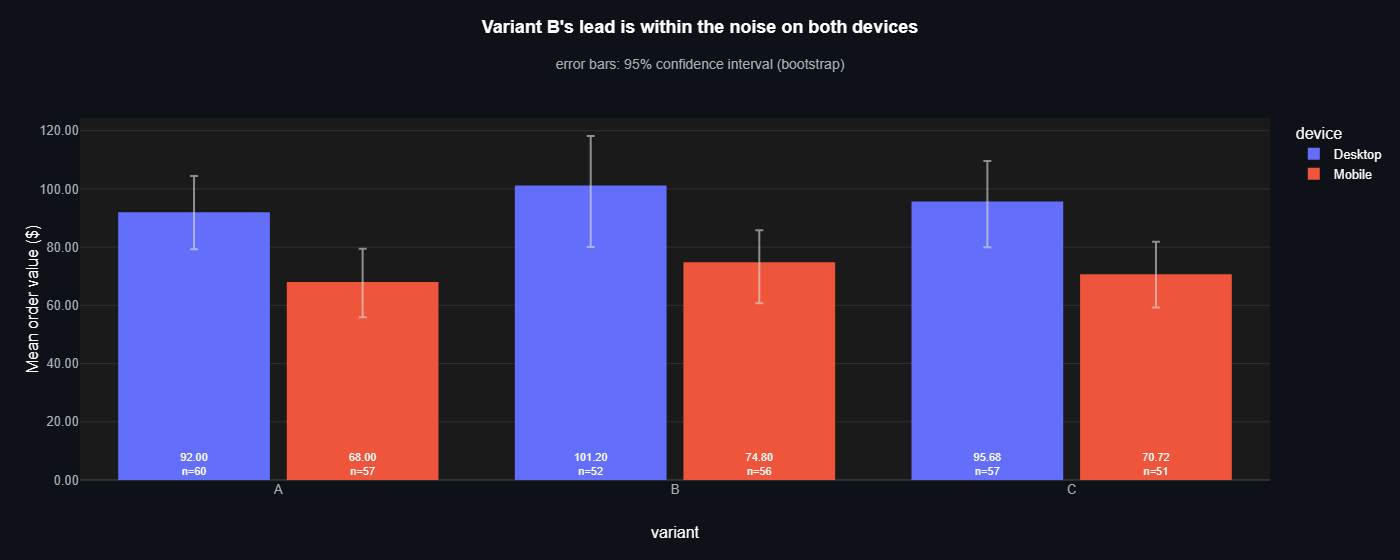

In [36]:
ev.bar_plot(
    checkout,
    "variant",
    "order_value",
    color="device",
    agg="mean",
    ci="bootstrap",
    show_n=True,
    value_format=",.2f",
    title="Variant B's lead is within the noise on both devices",
    y_title="Mean order value ($)",
)

**Which regions reached this year's revenue target?** Each region's 2025 revenue,
ranked, against a target of 475k, with the bars coloured above or below it.

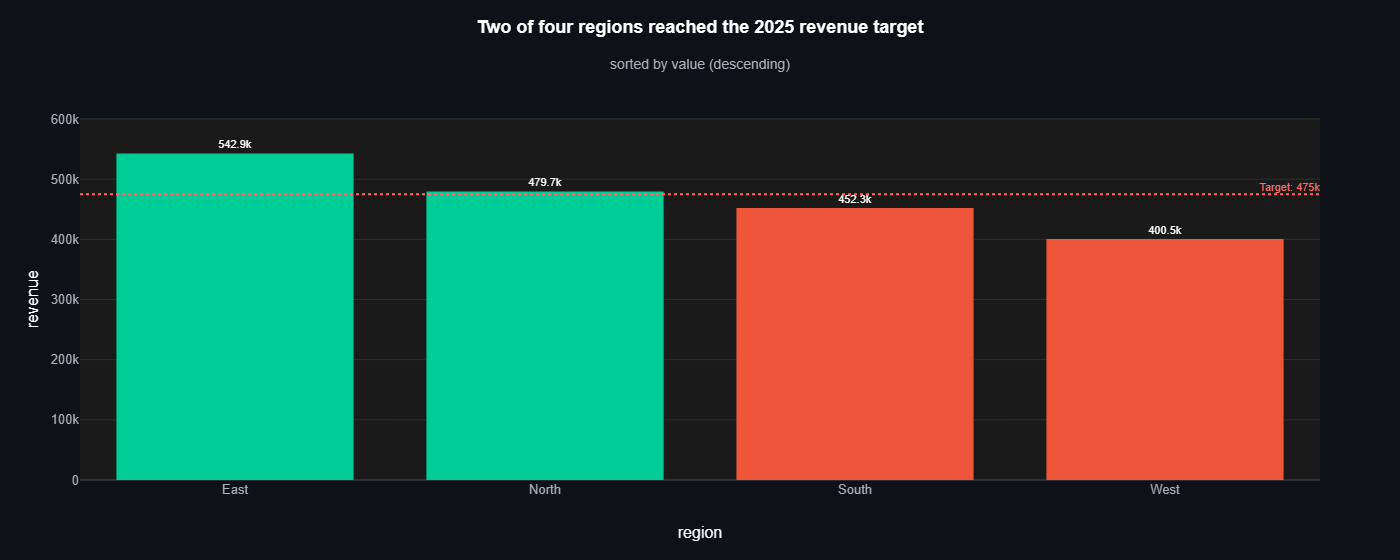

In [37]:
regions_2025 = db.sql("""
    SELECT region, SUM(revenue) AS revenue
    FROM orders JOIN customers USING (customer_id)
    WHERE year(order_date) = 2025
    GROUP BY region
    ORDER BY region
""")

ev.bar_plot(
    regions_2025,
    "region",
    "revenue",
    sort_by="value",
    target=475_000,
    color_by_value="sign",
    color_midpoint=475_000,
    title="Two of four regions reached the 2025 revenue target",
)

## Limits

`bar_plot` refuses an ambiguous request rather than guess, and every message names the
options involved and how to fix it. These are all the option pairs that conflict, with
the error each one gives.

In [38]:
conflicts = {
    "a list y and color": {"y": ["revenue", "profit"], "color": "warehouse"},
    "color the same column as x": {"y": "revenue", "agg": "sum", "color": "region"},
    "an interval without raw rows": {"y": "revenue", "ci": "bootstrap"},
    "a standard error of a median": {"y": "revenue", "agg": "median", "ci": "sem"},
    "error bars on stacked bars": {
        "y": "revenue",
        "color": "warehouse",
        "agg": "mean",
        "ci": "sem",
        "barmode": "stack",
    },
    "an average line on 100 % bars": {
        "color": "warehouse",
        "agg": "count",
        "barmode": "percent",
        "avg_line": True,
    },
    "a target on 100 % bars": {
        "color": "warehouse",
        "agg": "count",
        "barmode": "percent",
        "target": 0.5,
    },
    "shares of the total on 100 % bars": {
        "color": "warehouse",
        "agg": "count",
        "barmode": "percent",
        "show_pct_of_total": True,
    },
    "Other without top_n": {"y": "revenue", "agg": "sum", "other": True},
    "row counts without agg": {"y": "revenue", "show_n": True},
    "highlight with several series": {
        "y": "revenue",
        "agg": "sum",
        "color": "warehouse",
        "highlight": "North",
    },
    "highlight with a list y": {
        "y": ["revenue", "profit"],
        "agg": "sum",
        "highlight": "North",
    },
    "highlight and value colours": {
        "y": "revenue",
        "agg": "sum",
        "highlight": "North",
        "color_by_value": "sign",
    },
    "value colours with several series": {
        "y": "revenue",
        "agg": "sum",
        "color": "warehouse",
        "color_by_value": "sign",
    },
    "value colours with a list y": {
        "y": ["revenue", "profit"],
        "agg": "sum",
        "color_by_value": "sign",
    },
    "value colours and a colour map": {
        "y": "revenue",
        "agg": "sum",
        "color_by_value": "sign",
        "color_map": WAREHOUSE_COLORS,
    },
    "a colour scale without value colours": {
        "y": "revenue",
        "agg": "sum",
        "colorscale": "Viridis",
    },
    "a midpoint without value colours": {
        "y": "revenue",
        "agg": "sum",
        "color_midpoint": 0.0,
    },
    "a colour map with one series": {
        "y": "revenue",
        "agg": "sum",
        "color_map": WAREHOUSE_COLORS,
    },
}
for conflict, options in conflicts.items():
    try:
        ev.bar_plot(orders, "region", **options)
    except ValueError as error:
        print(f"{conflict}:\n    {error}\n")

a list y and color:
    bar_plot: y=['revenue', 'profit'] cannot be combined with color='warehouse'. Pick one shape: a list y for one column per series, or color for series stacked in one column.

color the same column as x:
    bar_plot: color='region' is the same column as x. color splits each category into series; to colour the bars themselves, use highlight or color_by_value.

an interval without raw rows:
    bar_plot: ci='bootstrap' needs agg='mean' or agg='median', got agg=None. Pass the raw rows with agg='mean' or 'median', or remove ci.

a standard error of a median:
    bar_plot: ci='sem' cannot be combined with agg='median'. The standard error describes a mean: use ci='bootstrap', or agg='mean'.

error bars on stacked bars:
    bar_plot: ci='sem' cannot be combined with barmode='stack'. Remove one of them.

an average line on 100 % bars:
    bar_plot: avg_line=True cannot be combined with barmode='percent'. Remove one of them.

a target on 100 % bars:
    bar_plot: target=0.

**Raw rows without `agg`.** With `agg=None`, each row is one bar, so a category that
appears twice is an error, never a silent sum.

In [39]:
try:
    ev.bar_plot(orders, "region", "revenue")
except ValueError as error:
    print(error)

bar_plot: 4 values of x appear in more than one row (e.g. region='North'), but agg=None plots each row as-is. Set agg (e.g. agg='sum') to combine them, or return one row per x from the query.


**Missing values.** Rows with a missing value in a column the chart uses are dropped,
and a warning says how many. Median income per segment drops the customers who
skipped the income question, and the warning is the first hint that most of them are
Students (*Missing not at random*, pattern 7).

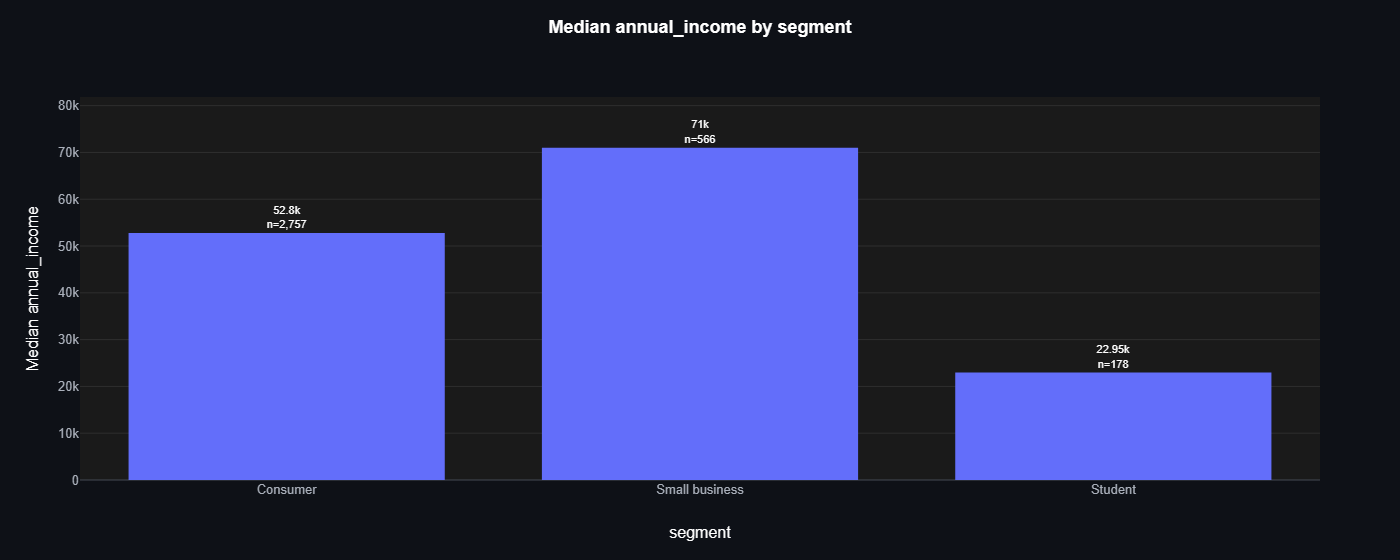

In [40]:
income = db.sql("SELECT segment, annual_income FROM customers ORDER BY customer_id")
ev.bar_plot(income, "segment", "annual_income", agg="median", show_n=True)

**A time axis stays in time order.** A date column gives bars on a calendar axis, here
monthly orders with the April 2025 price rise visible as a step down. Sorting or cutting
dates would break the timeline, so `sort_by`, `top_n` and `highlight` refuse a time
`x`.

bar_plot: sort_by='value' cannot be used with x='month', a time column. A time axis is always in time order: remove sort_by, or cast x to text in the query.


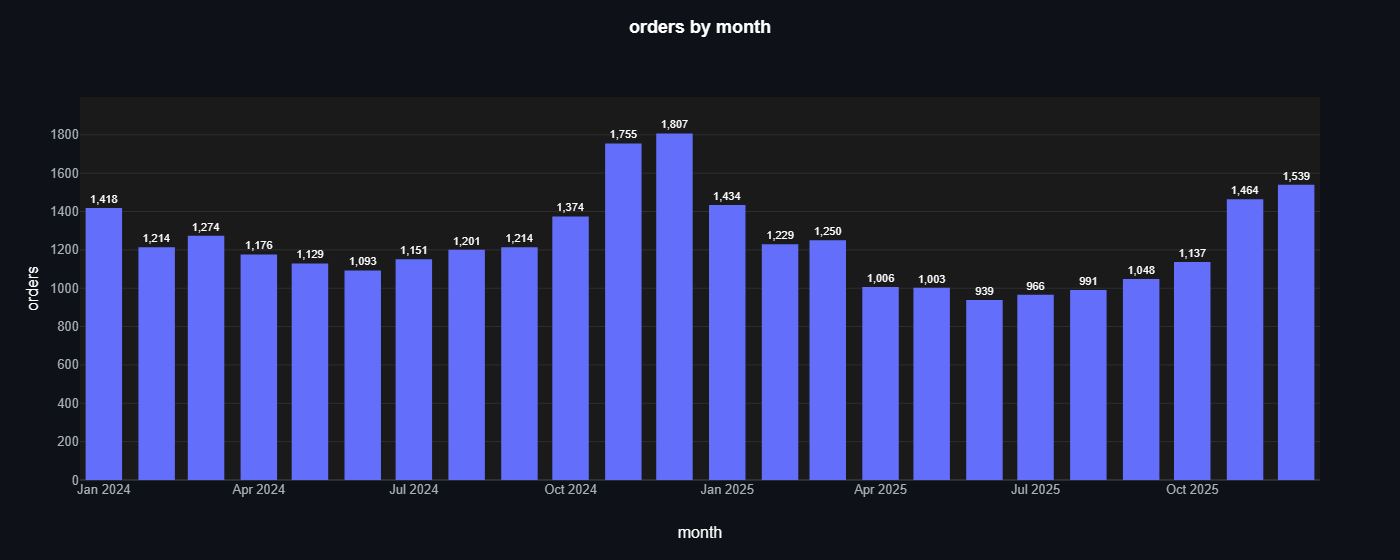

In [41]:
monthly = db.sql("""
    SELECT date_trunc('month', date) AS month, SUM(orders) AS orders
    FROM daily_metrics
    GROUP BY month
    ORDER BY month
""")
try:
    ev.bar_plot(monthly, "month", "orders", sort_by="value")
except ValueError as error:
    print(error)
ev.bar_plot(monthly, "month", "orders")

**100 % bars need values of 0 or more**, since a share of a negative total means
nothing. **An option that does nothing in the current mode warns** instead of being
silently ignored, here a sort direction without a sort.

bar_plot: barmode='percent' needs values of 0 or more, but some are negative. Use barmode='stack' or 'group', or filter the negative values.


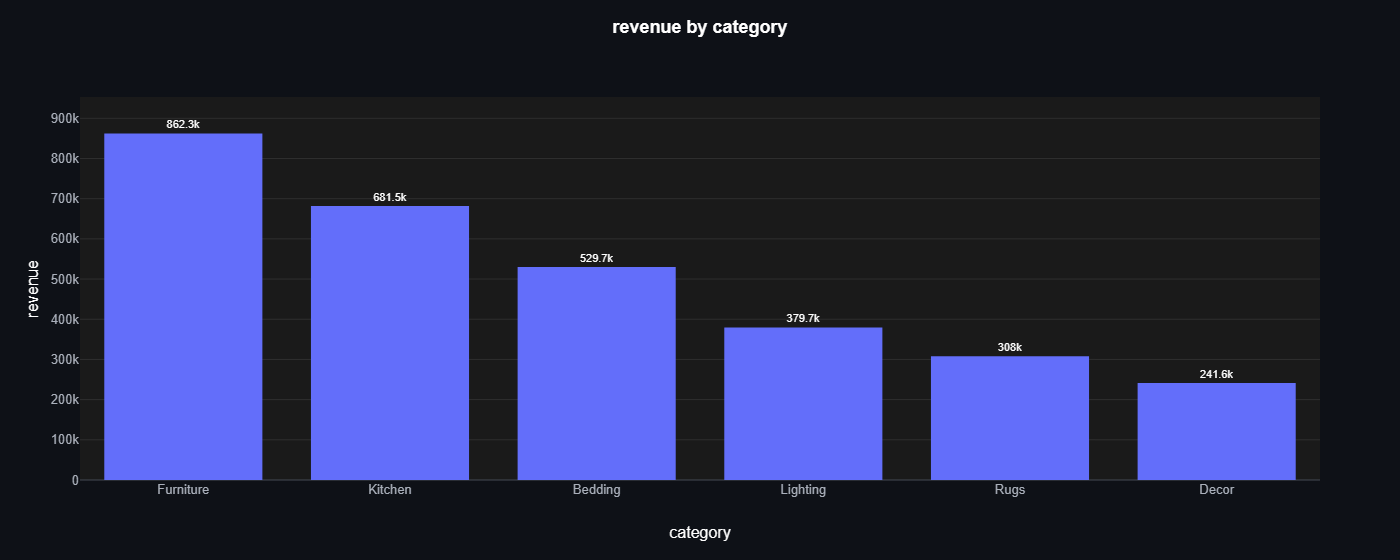

In [42]:
change_by_hub = db.sql("""
    SELECT category, warehouse,
           SUM(revenue) FILTER (WHERE year(order_date) = 2025)
             / SUM(revenue) FILTER (WHERE year(order_date) = 2024) - 1 AS revenue_change
    FROM orders JOIN products USING (product_id)
    GROUP BY category, warehouse
    ORDER BY category, warehouse
""")
try:
    ev.bar_plot(
        change_by_hub,
        "category",
        "revenue_change",
        color="warehouse",
        barmode="percent",
    )
except ValueError as error:
    print(error)
ev.bar_plot(categories, "category", "revenue", ascending=True)

## Insight story

**Which categories sell the biggest tickets on Black Friday weekend?** (*Small groups
at the top of a ranking*, pattern 11.) Merchandising wants to know where to put next
year's Black Friday promotion. Start with the plain ranking: mean order value per
category, highest first, with the small-group flag switched off.

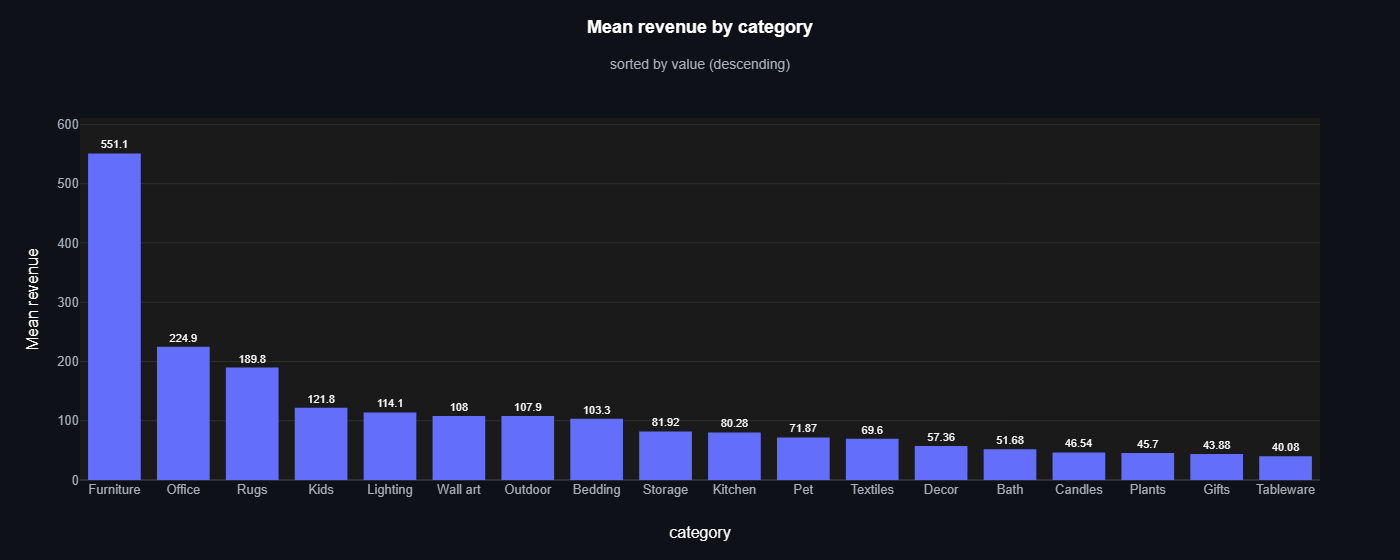

In [43]:
ev.bar_plot(weekend, "category", "revenue", agg="mean", sort_by="value", min_n=None)

Office comes second, ahead of Rugs and Lighting: a surprising candidate for a promotion.
The default small-group flag (`min_n=30`) hatches every bar built from fewer than 30
orders. That's most of the ranking, Office included.

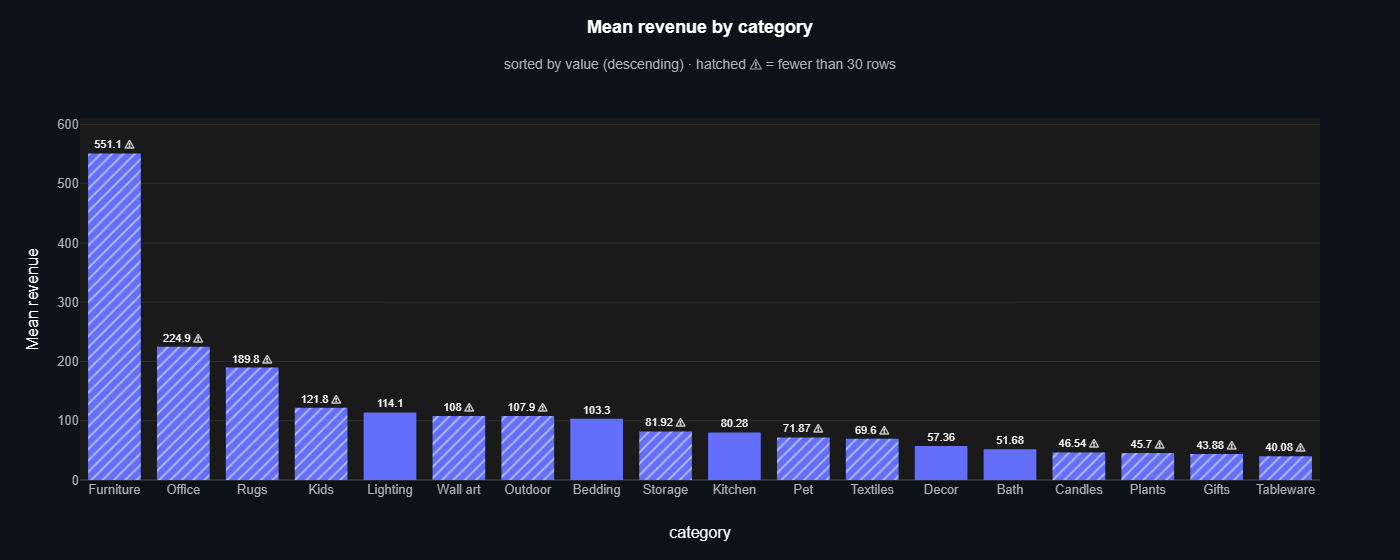

In [44]:
ev.bar_plot(weekend, "category", "revenue", agg="mean", sort_by="value")

How unreliable? Keep the top eight, write each bar's order count on it and add bootstrap
intervals. Office's second place rests on 3 orders, too few even for a trustworthy
interval, and the intervals of Office, Rugs and Kids overlap: their order is not
settled.

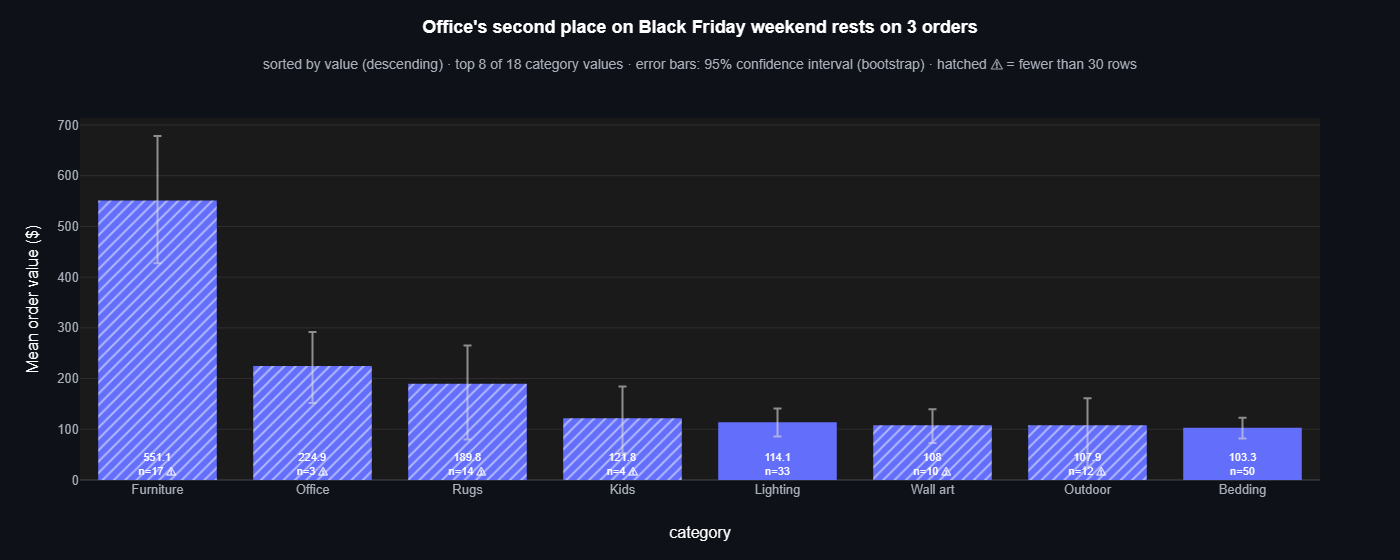

In [45]:
ev.bar_plot(
    weekend,
    "category",
    "revenue",
    agg="mean",
    sort_by="value",
    top_n=8,
    ci="bootstrap",
    show_n=True,
    title="Office's second place on Black Friday weekend rests on 3 orders",
    y_title="Mean order value ($)",
)

**Finding:** one weekend is too short to rank most categories. Only Furniture's lead is
clear; the order of the rest, Office's second place in particular, is chance. Plan
next year's promotion on a full season of orders, not on one weekend's averages.

## Escape hatch

The result is a plain Plotly figure, and every trace carries a role (`data` for the bars,
`reference` for lines and stack totals). A report might want the average line solid
and heavier than the default dashed one; select it by its role and group, and change
it with Plotly.

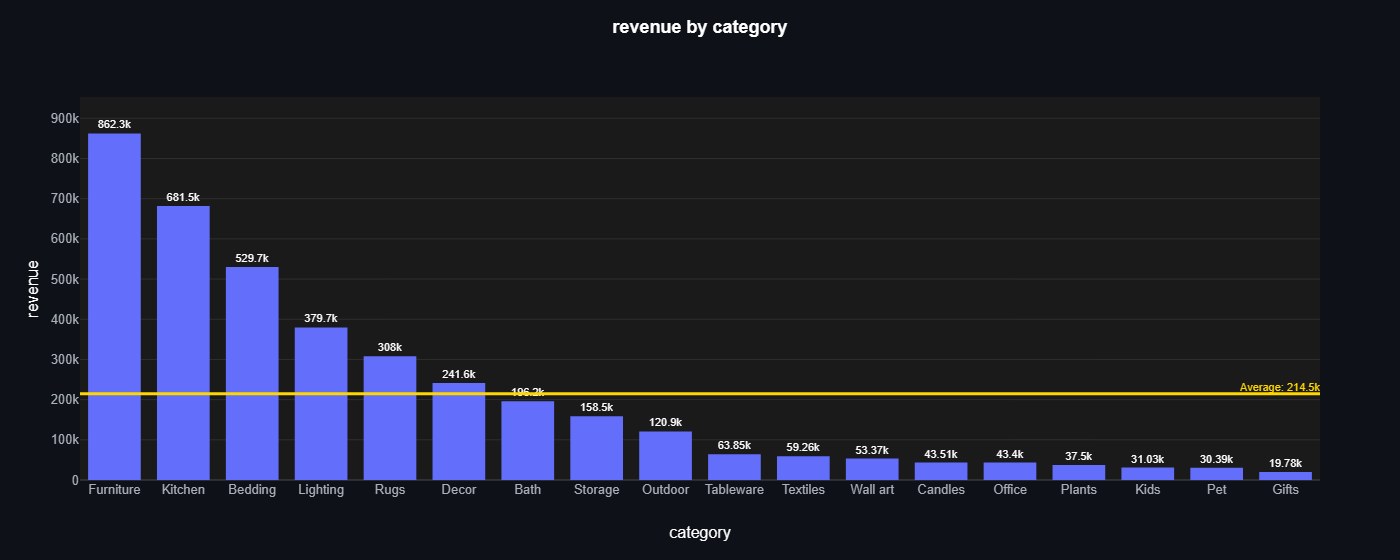

In [46]:
fig = ev.bar_plot(revenue, "category", "revenue", avg_line=True)
fig.update_traces(
    line_dash="solid",
    line_width=3,
    selector=lambda trace: trace.meta == {"role": "reference", "group": "average"},
)